<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QSVM_VanishingSimilarityDDoS_RodriguezAlmazan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum kernel SVM against vanishing similarity for DDoS detection: Rodriguez-Almazan et al. (2026) step by step

This notebook rebuilds the experiments of one paper:

Arturo Rodriguez-Almazan, Guillermo Rivas, Pablo Plaza, Angelica Gonzalez-Arrieta and Ricardo S. Alonso, "Mitigating vanishing similarity in quantum kernels for DDoS attack detection", *Quantum Machine Intelligence* 8, article 73 (2026). DOI 10.1007/s42484-026-00412-6.

**What the notebook does.** It downloads the NTP part of the CICDDoS2019 dataset, prepares it as the paper does (standardise, PCA, min-max to (0,1)), and builds two quantum kernels for a support vector machine: the usual fidelity kernel on `n` qubits, and the paper's new kernel, which is the average of `n` small three-qubit kernels. It then repeats the paper's three experiments, shows the "vanishing similarity" (kernel concentration) that the paper wants to remove, and compares every number with the paper.

**How to run it.** Open it in Google Colab, keep the normal CPU runtime, and choose Runtime, then Run all. No GPU and no IBM account are needed: every circuit is simulated exactly on the CPU. Downloading the 645 MB data file takes a few minutes the first time. With `FAST_MODE = True` (the default in the configuration cell) the notebook finishes in about 10 minutes; with `FAST_MODE = False` it uses more random draws and a finer bandwidth grid and takes roughly half an hour to an hour.

**What you will get at the end.** Your own accuracy and F1 numbers next to the paper's, a plot of how the spread of the kernel values shrinks with the number of qubits for both kernels, the kernel matrices of the paper's Figures 6 to 8, and a verdict (reproduced, not reached, exceeded, cannot be checked) for each claim.

## 1. The paper in one page

**Problem.** A quantum support vector machine (QSVM) turns every data point into a quantum state and uses the overlap between two states as a similarity. When the number of qubits grows, the quantum state space grows exponentially, two different states are almost always nearly orthogonal, and the similarity is close to 0 for every pair of different points. The kernel matrix then looks like the identity matrix and the classifier learns nothing. This is called *vanishing similarity* or *kernel concentration*.

**Decision.** Each network flow gets one answer: attack (DDoS) or benign. The attack is NTP amplification, taken from CICDDoS2019.

**Method.**
* *Fidelity kernel* (paper Eq. 3 and 7): the cyclic ZZ feature map on `n` qubits, one qubit per feature, and `K(x, y) = |<phi(x)|phi(y)>|^2`.
* *Proposed kernel* (paper Eq. 8): for each feature `a` take a window of three features `(a-1, a, a+1)` and use the same ZZ feature map on only three qubits (without the wrap-around coupling). That gives `n` small kernels; the final kernel is their average. This mimics classical multiple kernel learning. The space of each small kernel has only 2^3 = 8 dimensions, so it cannot concentrate.
* Both kernels feed a classical SVM (`SVC` with a precomputed kernel).

**Data.** CICDDoS2019, NTP-based DDoS attacks against benign traffic: after removing the textual columns, about 82 numeric features and more than one million flows. Three experiments use subsets of 1500, 25 and 100 flows.

**Preprocessing.** Standardise each feature, reduce with PCA to as many components as qubits, rescale each component with min-max to the interval (0, 1). The split is 70% training and 30% test.

**Claims to check.**
1. Experiment 1 (1500 flows, 2 features, Table 1): ZZ map accuracy 0.995 and F1 0.996, angle encoding 0.720 and 0.819, classical RBF SVC 0.993 and 0.995.
2. Experiment 2 (25 flows, 4 to 16 features, Table 2): the fidelity kernel falls from 0.875 to 0.375 accuracy while the proposed kernel stays at 0.875; the kernel matrices (Figs. 6 and 7) show that the fidelity kernel loses its off-diagonal entries and the proposed one keeps them.
3. Experiment 3 (100 flows, 20 features, Table 3 and Fig. 8): accuracy 0.867 (fidelity), 1.000 (proposed), 0.933 (RBF), 0.933 (multiple RBF over the same feature windows); the multiple-RBF baseline matches the plain RBF, so the gain is not due to the window decomposition alone.
4. Appendix A: a Haar-random bound on the variance of the kernel, about 1/2^(2n) for the fidelity kernel and about 1/2^(2m) for the proposed kernel with window size m = 3.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset file | CICDDoS2019, NTP-based DDoS attacks (benign vs DrDoS_NTP) | Hugging Face mirror `baalajimaestro/CICDDoS2019`, file `01-12/DrDoS_NTP.csv` (1 202 642 attack and 14 365 benign flows) |
| Sampling | Subsets of 1500, 25 and 100 flows, class balance not stated | `# CHOICE:` class-balanced random subsets; the file holds 84 attack flows per benign flow, so an unbalanced draw would be trivial |
| Features | "82 features after removing qualitative information" | `# CHOICE:` also drop Unnamed index, flow id, IP addresses, ports, timestamp; drop constant columns; the rest (see Section 4) is standardised |
| Scaling and PCA | Fitted on the whole selected subset, train and test together (the authors flag this as a limitation) | `# CHOICE:` every transform is fitted on the training split only; one ablation in Experiment 1 repeats the paper's protocol |
| Min-max range | (0, 1) | (0, 1), test values clipped to [0, 1] |
| Feature map | Cyclic ZZ map, Eq. 7: `exp[i sum (pi-x_a)(pi-x_{a+1}) Z_a Z_{a+1} + i sum x_a Z_a] H^n` | Exactly Eq. 7, one repetition (`reps = 1`), built from `H`, `RZ(-2x)` and `RZZ(-2(pi-x_a)(pi-x_b))`; for n = 2 the cyclic sum counts the single pair twice, as the equation literally says |
| Angle encoding (Exp. 1) | Not specified | `# CHOICE:` one `RY(x_a)` per qubit with x in (0, 1) |
| Window of the proposed kernel | Features a-1, a, a+1, wrap-around indices, 3 qubits, no cyclic coupling | Same, indices taken modulo n |
| Kernel evaluation | Not specified (statevector or sampler) | Exact simulation: a closed form for the diagonal ZZ map (fast, up to 20 qubits), checked against Qiskit's `FidelityStatevectorKernel` on the executed circuits |
| SVM | Not specified | `SVC(C=1.0)`; RBF baseline with `gamma="scale"` |
| Multiple-RBF baseline | RBF kernels averaged over the same feature windows | `# CHOICE:` `gamma = 1/(3 * variance of the window)` for each window, fitted on the training split |
| Bandwidth | None (features in (0, 1) are used as angles directly) | Paper-faithful runs use bandwidth 1. An extra run tunes the bandwidth on a validation split of the training data |
| Number of runs | One draw per experiment | One draw as in the paper (draw 0), plus many random draws, because 8 and 30 test points are very noisy |

## 2. Install the libraries

Colab already has NumPy, pandas, scikit-learn and Matplotlib. We add Qiskit, its machine learning package and the Aer simulator at the versions this notebook was tested with, plus `pylatexenc` (needed to draw circuits). If Colab asks you to restart the session after the installation, restart it and run the notebook again from the top. On a machine where these packages are already installed, the cell does nothing.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    try:
        import qiskit, qiskit_machine_learning, qiskit_aer, pylatexenc  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "qiskit-aer==0.17.2",
                           "pylatexenc", "huggingface_hub"])
    print("Installed. If imports fail below, restart the session (Runtime > Restart session) and Run all again.")
else:
    print("Qiskit packages already present; nothing to install.")

Qiskit packages already present; nothing to install.


## 3. Configuration

Every number you may want to change is in the next cell. `FAST_MODE = True` gives a class demonstration in about ten minutes (fewer random draws, a coarser bandwidth grid). `FAST_MODE = False` is the full run. The three experiment sizes follow the paper.

**About the data download.** CICDDoS2019 is public on Hugging Face and needs no token. If you ever point `HF_REPO` at a gated mirror, add your own token in Colab (left side bar, key icon, Secrets, name `HF_TOKEN`); the cell after the configuration looks it up and never prints it.

In [2]:
SEED = 42
FAST_MODE = False                      # True: about 10 minutes. False: full run

# data
HF_REPO = "baalajimaestro/CICDDoS2019"
HF_FILE = "01-12/DrDoS_NTP.csv"        # NTP amplification attacks + benign flows
DATA_SOURCE = "huggingface"            # "huggingface" or "path"
LOCAL_PATH = ""                        # used when DATA_SOURCE == "path"
DATA_DIR = "qc090_data"                # cache directory (created if needed)
ATTACK_KEEP = 0.02                     # CHOICE: keep 2 % of the 1.2 M attack flows while scanning the file
TEST_SIZE = 0.3                        # paper: 70 % / 30 %

# experiment sizes (paper)
EXP1_N, EXP1_FEATURES = 1500, 2
EXP2_N, EXP2_FEATURES = 25, [4, 6, 8, 10, 16]
EXP3_N, EXP3_FEATURES = 100, 20
M_WINDOW = 3                           # qubits of every I-kernel (paper: m = 3)
SHOTS = 4096                           # only for the shot-noise illustration

if FAST_MODE:
    EXP2_DRAWS = 8                     # random draws of the 25-flow experiment
    EXP3_DRAWS = 2                     # random draws of the 100-flow experiment
    TUNE_DRAWS = 1                     # draws that also get a tuned bandwidth
    BANDWIDTH_GRID = [0.25, 0.5, 1.0, 2.0]
    CONC_POINTS = 30                   # flows used to measure kernel concentration
    CONC_QUBITS = [2, 4, 6, 8, 10, 12, 16, 20]
else:
    EXP2_DRAWS = 30
    EXP3_DRAWS = 10
    TUNE_DRAWS = 5
    BANDWIDTH_GRID = [0.1, 0.25, 0.5, 1.0, 2.0]
    CONC_POINTS = 40
    CONC_QUBITS = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]

IBM_TOKEN = ""                         # not needed: everything is simulated exactly
print("FAST_MODE =", FAST_MODE, "| draws:", EXP2_DRAWS, EXP3_DRAWS, TUNE_DRAWS, "| grid:", BANDWIDTH_GRID)

FAST_MODE = False | draws: 30 10 5 | grid: [0.1, 0.25, 0.5, 1.0, 2.0]


In [3]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(not needed for this public dataset)")

Hugging Face token available: True (not needed for this public dataset)


In [4]:
import os, time, json, warnings
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import rbf_kernel

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore", category=FutureWarning)
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

def seconds_since(t0): return time.perf_counter() - t0
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2


## 4. The data: CICDDoS2019, NTP attacks

CICDDoS2019 (Canadian Institute for Cybersecurity) records network flows and describes each flow with about 80 statistics (packet counts, packet lengths, inter-arrival times, flag counts) plus a label. The file `DrDoS_NTP.csv` holds benign flows and flows of the NTP amplification attack, where the attacker abuses public time servers to flood a victim.

The file has about 1.2 million rows, so we read it in pieces of 100 000 rows. While scanning we keep all benign flows, a random 2% of the attack flows (enough for the sizes below), and the exact count of every label in the full file. The sampled pool is cached in `DATA_DIR`, so the second run does not read the 645 MB file again.

In [5]:
POOL_CACHE = os.path.join(DATA_DIR, "pool_ntp.csv.gz")
COUNT_CACHE = os.path.join(DATA_DIR, "label_counts.json")

def get_csv_path():
    if DATA_SOURCE == "path":
        return LOCAL_PATH
    from huggingface_hub import hf_hub_download
    print("Downloading (or reusing) the file", HF_FILE, "from", HF_REPO, "...")
    return hf_hub_download(repo_id=HF_REPO, filename=HF_FILE, repo_type="dataset",
                           local_dir=DATA_DIR, token=HF_TOKEN)

def scan_and_sample(csv_path):
    kept, counts = [], {}
    for chunk in pd.read_csv(csv_path, chunksize=100_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()          # original headers start with spaces
        lab = chunk["Label"].astype(str).str.strip()
        for k, v in lab.value_counts().items():
            counts[k] = counts.get(k, 0) + int(v)
        kept.append(chunk[lab == "BENIGN"])
        kept.append(chunk[lab != "BENIGN"].sample(frac=ATTACK_KEEP, random_state=SEED))
    return pd.concat(kept, ignore_index=True), counts

t0 = time.perf_counter()
if os.path.exists(POOL_CACHE) and os.path.exists(COUNT_CACHE):
    pool = pd.read_csv(POOL_CACHE, low_memory=False)
    full_counts = json.load(open(COUNT_CACHE))
    print("Loaded the cached pool from", POOL_CACHE)
else:
    pool, full_counts = scan_and_sample(get_csv_path())
    pool.to_csv(POOL_CACHE, index=False, compression="gzip")
    json.dump(full_counts, open(COUNT_CACHE, "w"))
print(f"Pool shape {pool.shape} in {seconds_since(t0):.0f} s")
print("Label counts in the FULL file:", full_counts)

Loaded the cached pool from qc090_data\pool_ntp.csv.gz
Pool shape (38417, 88) in 4 s
Label counts in the FULL file: {'DrDoS_NTP': 1202642, 'BENIGN': 14365}


### Cleaning and labels

Following the paper, text columns are removed. We also remove everything that identifies a flow instead of describing its behaviour (index column, flow id, IP addresses, ports, timestamp). Then the usual cleaning: numbers only, remove infinite and missing values, drop duplicate rows and constant columns. The label becomes 1 for the attack (`DrDoS_NTP`, the positive class) and 0 for `BENIGN`.

In [6]:
ID_COLUMNS = ["Unnamed: 0", "Flow ID", "Source IP", "Source Port", "Destination IP",
              "Destination Port", "Timestamp", "SimillarHTTP"]          # CHOICE: identifiers are not features

lab_raw = pool["Label"].astype(str).str.strip()
X_df = pool.drop(columns=[c for c in ID_COLUMNS + ["Label"] if c in pool.columns])
X_df = X_df.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
ok = X_df.notna().all(axis=1)
X_df, lab_raw = X_df[ok], lab_raw[ok]
dup = X_df.duplicated()
X_df, lab_raw = X_df[~dup], lab_raw[~dup]
X_df = X_df.loc[:, X_df.nunique() > 1]

FEATURE_NAMES = list(X_df.columns)
X_all = X_df.to_numpy(dtype=float)
y_all = (lab_raw != "BENIGN").astype(int).to_numpy()
CLASS_NAMES = {0: "BENIGN", 1: "DrDoS_NTP (attack)"}
print("Clean pool:", X_all.shape, "| benign:", int((y_all == 0).sum()), "| attack:", int((y_all == 1).sum()))
print("Numeric features kept:", len(FEATURE_NAMES), "(the paper reports 82 before our extra removal of ports and identifiers)")

def balanced_indices(n_total, seed):
    """Random class-balanced subset of the clean pool (n_total/2 flows per class)."""
    r = np.random.default_rng(seed)
    n1 = n_total // 2
    n0 = n_total - n1
    i0 = r.choice(np.where(y_all == 0)[0], n0, replace=False)
    i1 = r.choice(np.where(y_all == 1)[0], n1, replace=False)
    idx = np.concatenate([i0, i1]); r.shuffle(idx)
    return idx

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

Clean pool: (36188, 67) | benign: 13315 | attack: 22873
Numeric features kept: 67 (the paper reports 82 before our extra removal of ports and identifiers)


## 5. Preprocessing: standardise, PCA, min-max

The paper's three steps are (1) standardise each feature to mean 0 and variance 1, (2) reduce with PCA to as many components as qubits, (3) rescale every component to (0, 1) with min-max. The paper fits all three on the whole selected subset, test flows included, and says so openly. Here **every transform is fitted on the training split only**; the test flows are only transformed (and clipped to [0, 1] after the min-max). Later, Experiment 1 repeats the paper's way once to show how much that choice matters.

Why (0, 1)? The values are used as rotation angles in radians in the quantum circuit, so (0, 1) means rotations of at most about 57 degrees.

In [7]:
def preprocess(Xtr, Xte, n_comp, fit_on_all=False):
    """standardise -> PCA(n_comp) -> min-max (0, 1). Fitted on the training split only unless fit_on_all."""
    fit_set = np.vstack([Xtr, Xte]) if fit_on_all else Xtr
    scaler = StandardScaler().fit(fit_set)
    pca = PCA(n_components=n_comp, random_state=SEED).fit(scaler.transform(fit_set))
    raw_fit = pca.transform(scaler.transform(fit_set))
    raw_tr, raw_te = pca.transform(scaler.transform(Xtr)), pca.transform(scaler.transform(Xte))
    mm = MinMaxScaler((0.0, 1.0)).fit(raw_fit)
    return mm.transform(raw_tr), np.clip(mm.transform(raw_te), 0.0, 1.0), raw_tr, raw_te

def make_split(n_total, n_comp, seed, fit_on_all=False):
    idx = balanced_indices(n_total, seed)
    Xtr, Xte, ytr, yte = train_test_split(X_all[idx], y_all[idx], test_size=TEST_SIZE, stratify=y_all[idx], random_state=seed)
    A_tr, A_te, R_tr, R_te = preprocess(Xtr, Xte, n_comp, fit_on_all)
    return dict(A_tr=A_tr, A_te=A_te, R_tr=R_tr, R_te=R_te, ytr=ytr, yte=yte)

d1 = make_split(EXP1_N, EXP1_FEATURES, SEED)
print("Experiment 1 split:", d1["A_tr"].shape, d1["A_te"].shape, "| angle range train:", d1["A_tr"].min().round(3), d1["A_tr"].max().round(3))

Experiment 1 split: (1050, 2) (450, 2) | angle range train: 0.0 1.0


## 6. Dataset Exploration and Visualisation

This section looks at the real data before any model touches it: its size, its features, how many flows of each class exist, and what the flows look like after the paper's preprocessing. Everything below is computed from the downloaded CICDDoS2019 flows and their true labels.

In [8]:
print("Pool read from the file (all benign + sampled attacks):", pool.shape)
print("Clean pool used for sampling (numeric features only):", X_all.shape)
print(f"\n{len(FEATURE_NAMES)} feature names:")
for i in range(0, len(FEATURE_NAMES), 3):
    print("  " + " | ".join(f"{n:34s}" for n in FEATURE_NAMES[i:i + 3]))
print("\nOriginal label values and counts in the full DrDoS_NTP.csv:", full_counts)
print("Binary labels in the clean pool:", {CLASS_NAMES[k]: int((y_all == k).sum()) for k in (0, 1)})

Pool read from the file (all benign + sampled attacks): (38417, 88)
Clean pool used for sampling (numeric features only): (36188, 67)

67 feature names:
  Protocol                           | Flow Duration                      | Total Fwd Packets                 
  Total Backward Packets             | Total Length of Fwd Packets        | Total Length of Bwd Packets       
  Fwd Packet Length Max              | Fwd Packet Length Min              | Fwd Packet Length Mean            
  Fwd Packet Length Std              | Bwd Packet Length Max              | Bwd Packet Length Min             
  Bwd Packet Length Mean             | Bwd Packet Length Std              | Flow Bytes/s                      
  Flow Packets/s                     | Flow IAT Mean                      | Flow IAT Std                      
  Flow IAT Max                       | Flow IAT Min                       | Fwd IAT Total                     
  Fwd IAT Mean                       | Fwd IAT Std                    

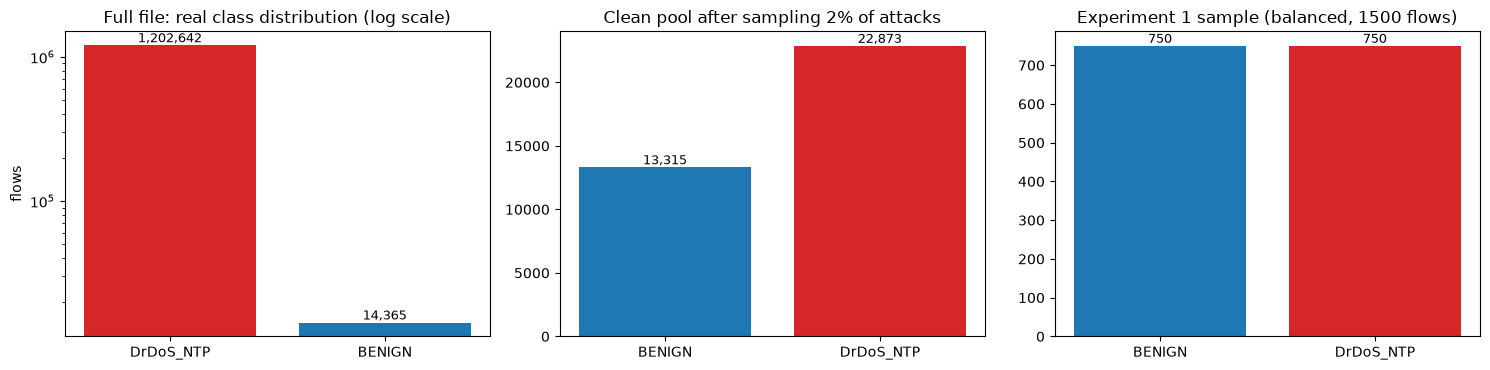

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
names = list(full_counts.keys()); vals = [full_counts[k] for k in names]
axes[0].bar(names, vals, color=["tab:blue" if n == "BENIGN" else "tab:red" for n in names])
axes[0].set_yscale("log"); axes[0].set_title("Full file: real class distribution (log scale)")
for i, v in enumerate(vals): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("flows")

counts_pool = [int((y_all == 0).sum()), int((y_all == 1).sum())]
axes[1].bar(["BENIGN", "DrDoS_NTP"], counts_pool, color=["tab:blue", "tab:red"])
axes[1].set_title(f"Clean pool after sampling {ATTACK_KEEP:.0%} of attacks")
for i, v in enumerate(counts_pool): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

counts_e1 = [int((d1["ytr"] == 0).sum() + (d1["yte"] == 0).sum()), int((d1["ytr"] == 1).sum() + (d1["yte"] == 1).sum())]
axes[2].bar(["BENIGN", "DrDoS_NTP"], counts_e1, color=["tab:blue", "tab:red"])
axes[2].set_title("Experiment 1 sample (balanced, 1500 flows)")
for i, v in enumerate(counts_e1): axes[2].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

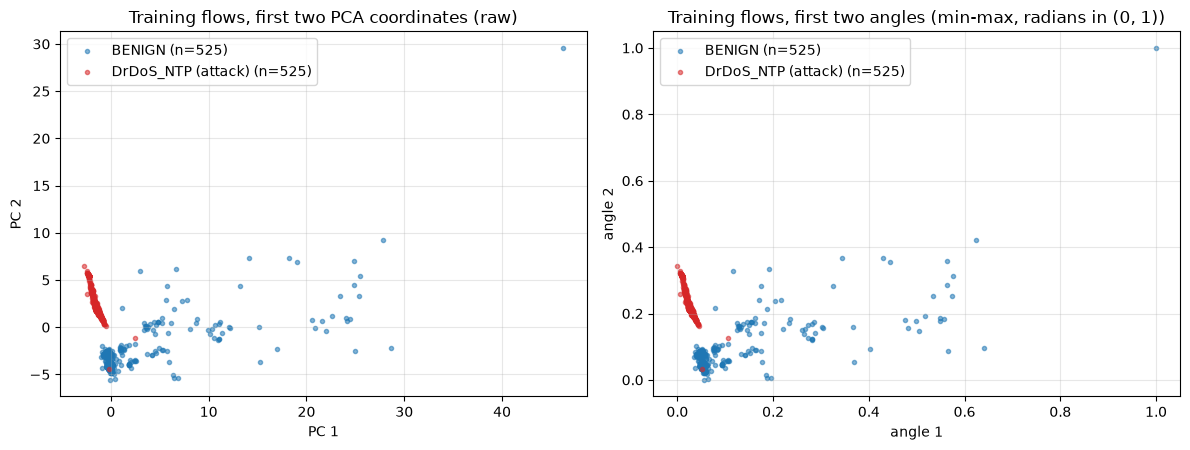

Variance explained by the first PCA components of the balanced sample: [0.233 0.164 0.127 0.05  0.044 0.04  0.038 0.037 0.03  0.028]


In [10]:
# 2-D scatter of the REAL Experiment 1 training flows, coloured by the ground-truth label.
# Left: raw PCA coordinates (PCA fitted on the standardised training split). Right: the same points
# after min-max scaling to (0, 1), i.e. the two rotation angles that the circuits receive.
colors = {0: "tab:blue", 1: "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, pts, title, xl in [(axes[0], d1["R_tr"], "Training flows, first two PCA coordinates (raw)", "PC 1"),
                           (axes[1], d1["A_tr"], "Training flows, first two angles (min-max, radians in (0, 1))", "angle 1")]:
    for k in (0, 1):
        m = d1["ytr"] == k
        ax.scatter(pts[m, 0], pts[m, 1], s=9, alpha=0.55, c=colors[k], label=f"{CLASS_NAMES[k]} (n={m.sum()})")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2")); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pca_full = PCA(n_components=10, random_state=SEED).fit(StandardScaler().fit_transform(X_all[balanced_indices(EXP1_N, SEED)]))
print("Variance explained by the first PCA components of the balanced sample:", pca_full.explained_variance_ratio_.round(3))

## 7. The two kernels

### 7.1 The cyclic ZZ feature map (paper Eq. 7)

For a vector `x` with `n` features the circuit uses `n` qubits and does three things:

1. a Hadamard `H` on every qubit, which puts each qubit into an equal superposition;
2. a rotation `exp(i x_a Z_a)` on qubit `a`, which writes the feature `x_a` into a phase;
3. for every neighbouring pair `(a, a+1)`, with the last qubit coupled back to the first (cyclic), a two-qubit rotation `exp(i (pi - x_a)(pi - x_{a+1}) Z_a Z_{a+1})`, which entangles neighbours and encodes the product of their features.

In the Qiskit gate set, `exp(i x Z)` is `RZ(-2x)` and `exp(i c Z Z)` is `RZZ(-2c)`.

### 7.2 Fidelity kernel and the proposed kernel

The *fidelity kernel* (Eq. 3) is `K(x, y) = |<phi(x)|phi(y)>|^2`, the probability to find all qubits in state 0 after running `U(x)` and then the inverse of `U(y)` (the "overlap test" of the paper's Fig. 1).

The *proposed kernel* (Eq. 8) averages `n` three-qubit kernels. The kernel number `a` sees only the three features `(x_{a-1}, x_a, x_{a+1})`, on a three-qubit ZZ map without the wrap-around coupling:

`K_new(x, y) = (1/n) * sum_a |<phi_3(x_a-window)|phi_3(y_a-window)>|^2`.

### 7.3 How the notebook computes them

The ZZ map is a diagonal phase layer after Hadamards, so its state is `2^(-n/2) * sum_z exp(i * phase(z, x)) |z>`, where `phase` is a cheap sum over bits. The overlap of two states is then a plain average of phases, which we compute exactly in NumPy, one block of bit strings at a time, so even 20 qubits (1 048 576 amplitudes) for 100 flows fit in a few seconds and a few hundred megabytes. To be sure this shortcut equals the real circuit, Section 9 compares it with Qiskit's `FidelityStatevectorKernel` running the drawn circuit.

In [11]:
# ---- exact kernel engine for the diagonal ZZ feature map (paper Eq. 7), pure NumPy
def zz_kernel(XA, XB=None, cyclic=True, chunk=1 << 15):
    """K[i, j] = |<phi(XA[i]) | phi(XB[j])>|^2 for U(x) = exp[i sum c_ab Z_a Z_b + i sum x_a Z_a] H^n.
    Basis state z has bit a = state of qubit a (Qiskit little-endian), Z eigenvalue s_a = (-1)^bit."""
    sym = XB is None
    XB = XA if sym else XB
    n = XA.shape[1]
    def pair_coeffs(X):
        c = (np.pi - X) * (np.pi - np.roll(X, -1, axis=1))     # (pi - x_a)(pi - x_{a+1})
        return c if cyclic else c[:, :-1]
    CA, CB = pair_coeffs(XA), pair_coeffs(XB)
    N = 1 << n
    acc = np.zeros((len(XA), len(XB)), dtype=complex)
    bits = np.arange(n)
    for s0 in range(0, N, chunk):
        z = np.arange(s0, min(N, s0 + chunk))
        S = (1 - 2 * ((z[:, None] >> bits) & 1)).astype(float)               # (chunk, n) of +-1
        SS = S * np.roll(S, -1, axis=1) if cyclic else S[:, :-1] * S[:, 1:]
        EA = np.exp(1j * (XA @ S.T + CA @ SS.T))                              # exp(i phase)
        EB = EA if sym else np.exp(1j * (XB @ S.T + CB @ SS.T))
        acc += EA.conj() @ EB.T
    return np.abs(acc / N) ** 2

def local_windows(n, m=M_WINDOW):
    assert m == 3, "the paper uses windows of three features"
    return [[(a - 1) % n, a, (a + 1) % n] for a in range(n)]

def local_kernel(XA, XB=None, m=M_WINDOW):
    """Proposed kernel (Eq. 8): mean over the n windows of the 3-qubit, non-cyclic ZZ kernel."""
    XB = XA if XB is None else XB
    n = XA.shape[1]
    K = np.zeros((len(XA), len(XB)))
    for idx in local_windows(n, m):
        K += zz_kernel(XA[:, idx], XB[:, idx], cyclic=False)
    return K / n

def angle_kernel(XA, XB):
    """Product-state angle encoding RY(x_a) on every qubit: K = prod_a cos^2((x_a - y_a)/2)."""
    return np.prod(np.cos((XA[:, None, :] - XB[None, :, :]) / 2) ** 2, axis=2)

def multi_rbf_kernel(XA, XB, Xtrain, m=M_WINDOW):
    """Classical multiple-RBF baseline: RBF kernels over the same windows, gamma = 1/(3 var(window)), then averaged."""
    K = 0
    for idx in local_windows(XA.shape[1], m):
        K = K + rbf_kernel(XA[:, idx], XB[:, idx], gamma=1.0 / (len(idx) * Xtrain[:, idx].var()))
    return K / XA.shape[1]

def fit_predict(Ktr, Kte, ytr):
    return SVC(kernel="precomputed", C=1.0).fit(Ktr, ytr).predict(Kte)
print("Kernel engine defined.")

Kernel engine defined.


## 8. Quantum Circuit Architecture

Below are the circuits that this notebook runs, built with Qiskit from the same definition as the NumPy engine above (Section 9 proves the two agree). There is no trainable quantum parameter: in a kernel method the circuit only encodes data, and training is the classical SVM. The paper does not give a gate-level drawing for the proposed kernel, only the 4-qubit example of Fig. 3, so the following are our readings of its Eq. 7 and 8:

* `reps = 1`: the equation has one layer of Hadamards followed by one diagonal layer;
* the two-qubit term is `RZZ(-2 (pi - x_a)(pi - x_b))` and the one-qubit term `RZ(-2 x_a)`, which equals the exponentials of Eq. 7 up to a global phase;
* for `n = 2` the cyclic sum visits the pair twice (pairs (0,1) and (1,0)), as written;
* the angle encoding of Experiment 1 is `RY(x)` per qubit (the paper does not say which rotation).

In [12]:
def zz_circuit(n, params=None, cyclic=True, name="ZZ"):
    """Paper Eq. 7: H on all qubits, RZ(-2 x_a) on each qubit, RZZ(-2 (pi - x_a)(pi - x_b)) on each coupled pair."""
    x = params if params is not None else ParameterVector("x", n)
    qc = QuantumCircuit(n, name=name)
    qc.h(range(n))
    for a in range(n):
        qc.rz(-2 * x[a], a)
    pairs = [(a, (a + 1) % n) for a in range(n)] if cyclic else [(a, a + 1) for a in range(n - 1)]
    for a, b in pairs:
        qc.rzz(-2 * (np.pi - x[a]) * (np.pi - x[b]), a, b)
    return qc

def angle_circuit(n, name="RY angle encoding"):
    x = ParameterVector("x", n)
    qc = QuantumCircuit(n, name=name)
    for a in range(n):
        qc.ry(x[a], a)
    return qc

def overlap_circuit(feature_map, xv, yv):
    """Overlap test (paper Fig. 1): U(x) followed by U(y)^dagger, then measure all qubits. P(0...0) = kernel value."""
    qc = feature_map.assign_parameters(list(xv)).compose(feature_map.assign_parameters(list(yv)).inverse())
    qc.measure_all()
    return qc

def describe(qc, label):
    n_params = len(qc.parameters)
    print(f"{label:46s} qubits={qc.num_qubits:2d}  depth={qc.depth():3d}  gates={dict(qc.count_ops())}  "
          f"data parameters={n_params}  trainable parameters=0")

rs = np.random.default_rng(SEED)
fm4 = zz_circuit(4)                      # the paper's Fig. 3 example: 4 features
fm2 = zz_circuit(2)                      # Experiment 1 (cyclic, 2 qubits)
fm3 = zz_circuit(3, cyclic=False, name="ZZ local window")   # one I-kernel of the proposed kernel
fa2 = angle_circuit(2)                   # Experiment 1 angle encoding
for lbl, c in [("Global cyclic ZZ map, n = 4 (paper Fig. 3)", fm4), ("Global cyclic ZZ map, n = 2 (Experiment 1)", fm2),
               ("Local 3-qubit ZZ map (one I-kernel)", fm3), ("RY angle encoding, n = 2 (Experiment 1)", fa2)]:
    describe(c, lbl)
for n in (6, 10, 16, 20):
    describe(zz_circuit(n), f"Global cyclic ZZ map, n = {n} (executed in Exp. 2/3)")

Global cyclic ZZ map, n = 4 (paper Fig. 3)     qubits= 4  depth=  6  gates={'h': 4, 'rz': 4, 'rzz': 4}  data parameters=4  trainable parameters=0
Global cyclic ZZ map, n = 2 (Experiment 1)     qubits= 2  depth=  4  gates={'h': 2, 'rz': 2, 'rzz': 2}  data parameters=2  trainable parameters=0
Local 3-qubit ZZ map (one I-kernel)            qubits= 3  depth=  4  gates={'h': 3, 'rz': 3, 'rzz': 2}  data parameters=3  trainable parameters=0
RY angle encoding, n = 2 (Experiment 1)        qubits= 2  depth=  1  gates={'ry': 2}  data parameters=2  trainable parameters=0
Global cyclic ZZ map, n = 6 (executed in Exp. 2/3) qubits= 6  depth=  8  gates={'h': 6, 'rz': 6, 'rzz': 6}  data parameters=6  trainable parameters=0
Global cyclic ZZ map, n = 10 (executed in Exp. 2/3) qubits=10  depth= 12  gates={'h': 10, 'rz': 10, 'rzz': 10}  data parameters=10  trainable parameters=0
Global cyclic ZZ map, n = 16 (executed in Exp. 2/3) qubits=16  depth= 18  gates={'h': 16, 'rz': 16, 'rzz': 16}  data parameters=1

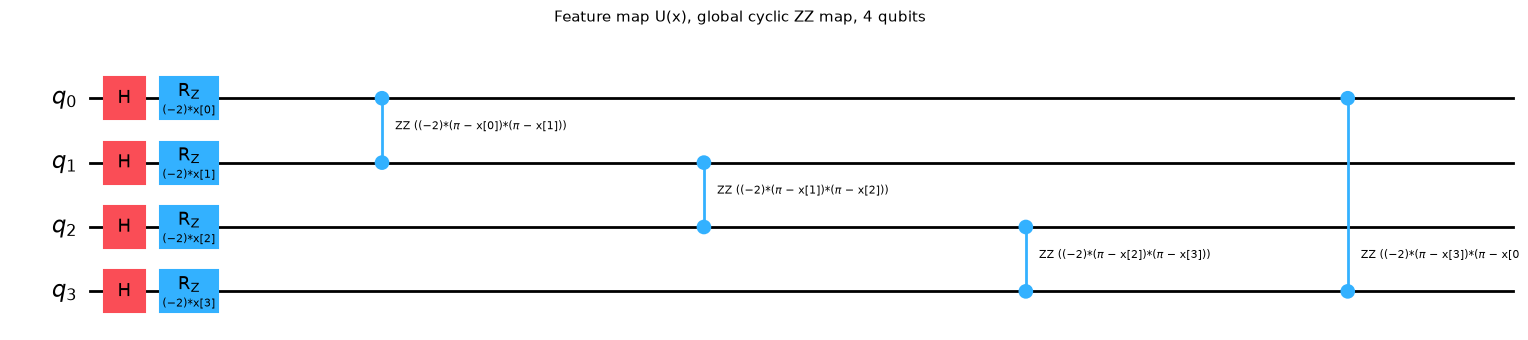

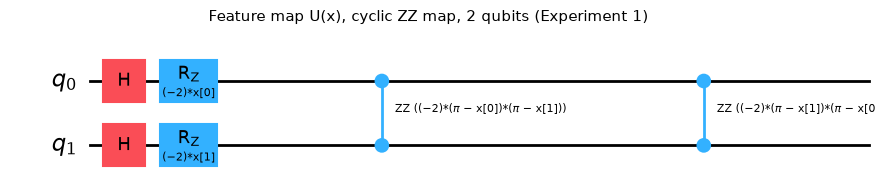

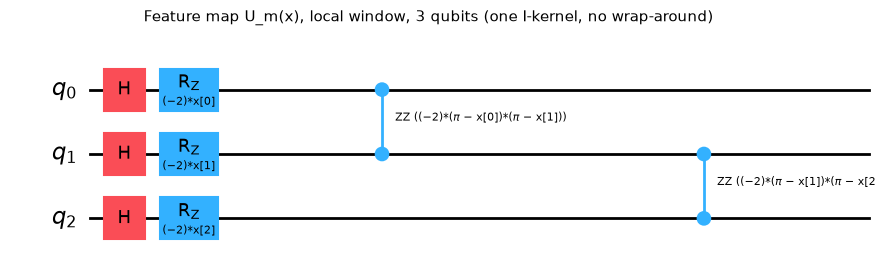

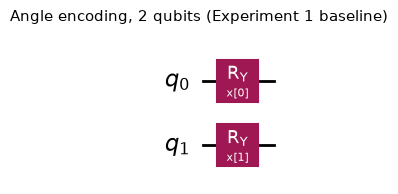

In [13]:
for qc, title in [(fm4, "Feature map U(x), global cyclic ZZ map, 4 qubits"), (fm2, "Feature map U(x), cyclic ZZ map, 2 qubits (Experiment 1)"),
                  (fm3, "Feature map U_m(x), local window, 3 qubits (one I-kernel, no wrap-around)"),
                  (fa2, "Angle encoding, 2 qubits (Experiment 1 baseline)")]:
    fig = qc.draw("mpl", fold=30)
    fig.suptitle(title, fontsize=11); display(fig); plt.close(fig)

Overlap-test circuit, global n = 4             qubits= 4  depth= 13  gates={'h': 8, 'rz': 8, 'rzz': 8, 'measure': 4, 'barrier': 1}  data parameters=0  trainable parameters=0


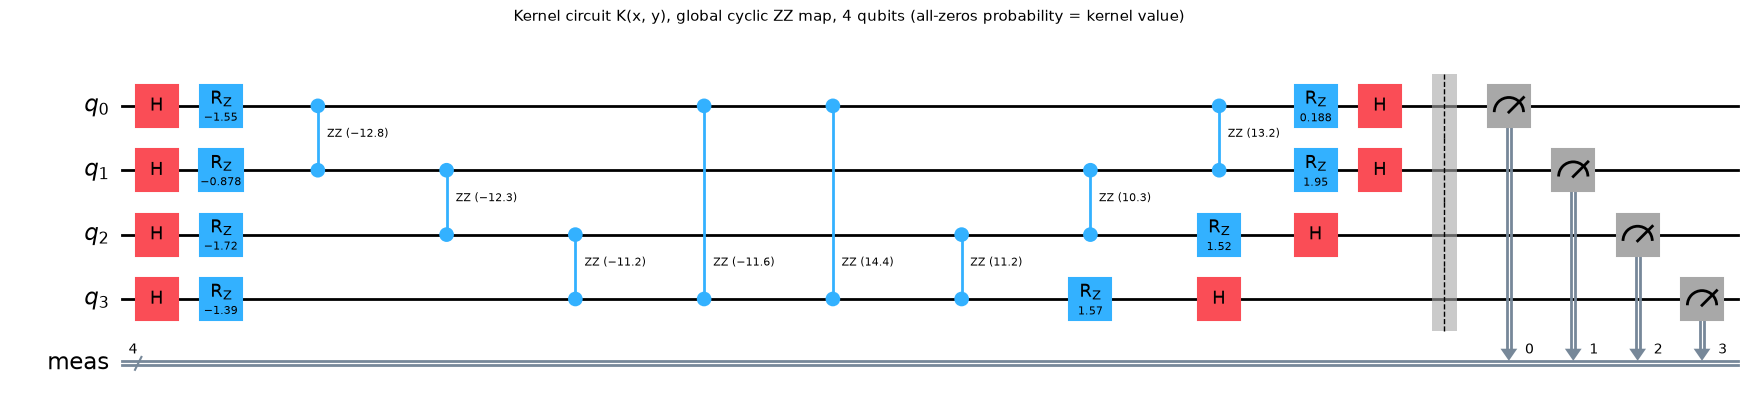

Overlap-test circuit, one local I-kernel (3 qubits) qubits= 3  depth=  9  gates={'h': 6, 'rz': 6, 'rzz': 4, 'measure': 3, 'barrier': 1}  data parameters=0  trainable parameters=0


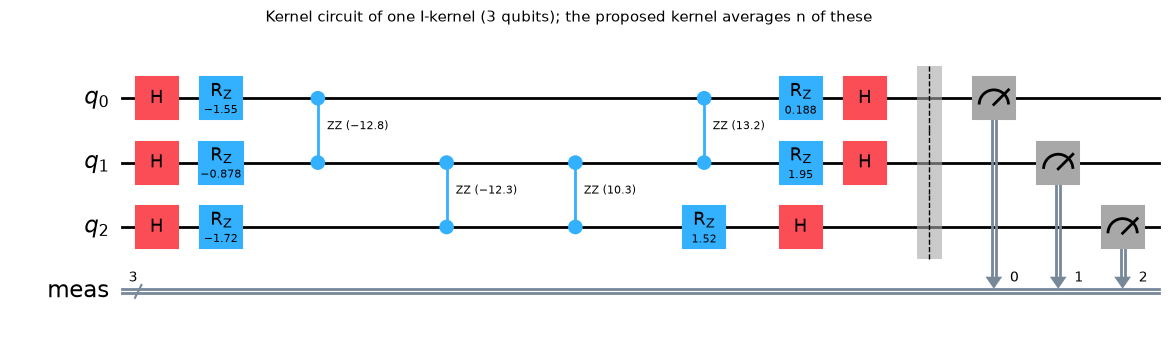

P(0000) from 4096 shots = 0.0049; exact kernel value (engine) = 0.0050; standard error ~ 0.0011


In [14]:
# The circuits that actually produce a kernel value: the overlap test U(x) then U(y)^dagger, measure everything.
x_demo, y_demo = rs.random(4), rs.random(4)
oc4 = overlap_circuit(fm4, x_demo, y_demo)
describe(oc4, "Overlap-test circuit, global n = 4")
fig = oc4.draw("mpl", fold=45); fig.suptitle("Kernel circuit K(x, y), global cyclic ZZ map, 4 qubits (all-zeros probability = kernel value)", fontsize=11); display(fig); plt.close(fig)

oc3 = overlap_circuit(fm3, x_demo[:3], y_demo[:3])
describe(oc3, "Overlap-test circuit, one local I-kernel (3 qubits)")
fig = oc3.draw("mpl", fold=45); fig.suptitle("Kernel circuit of one I-kernel (3 qubits); the proposed kernel averages n of these", fontsize=11); display(fig); plt.close(fig)

# Shot-based run of the drawn 4-qubit circuit versus the exact value: this is what hardware would do.
sim = AerSimulator(seed_simulator=SEED)
counts = sim.run(transpile(oc4, sim, seed_transpiler=SEED), shots=SHOTS, seed_simulator=SEED).result().get_counts()
p0 = counts.get("0" * 4, 0) / SHOTS
exact = float(zz_kernel(x_demo[None, :], y_demo[None, :])[0, 0])
print(f"P(0000) from {SHOTS} shots = {p0:.4f}; exact kernel value (engine) = {exact:.4f}; "
      f"standard error ~ {np.sqrt(exact * (1 - exact) / SHOTS):.4f}")

## 9. Check that the fast engine is the real circuit

Two independent checks, as in the other notebooks of this series:

1. **Library check.** Qiskit's `FidelityStatevectorKernel` simulates the drawn circuit and computes `|<phi(x)|phi(y)>|^2`. We compare it entry by entry with the NumPy engine for several qubit numbers, for the local kernel, and for the angle encoding.
2. **Direct statevector check.** For 16 and 20 qubits we build the full statevector of the circuit for a few pairs of flows and take the overlap by hand.

In [15]:
tol = 1e-10
rv = np.random.default_rng(SEED)
rows = []
for n in (2, 3, 4, 6, 8, 10, 12):
    X = rv.random((5, n))
    K_lib = FidelityStatevectorKernel(feature_map=zz_circuit(n), enforce_psd=False).evaluate(X, X)
    K_eng = zz_kernel(X)
    rows.append(("global ZZ", n, np.abs(K_lib - K_eng).max()))
    assert np.allclose(K_lib, K_eng, atol=tol), f"global ZZ mismatch at n={n}"

# local (proposed) kernel for n = 6 against the average of library 3-qubit kernels
X = rv.random((5, 6))
K_lib = np.zeros((5, 5))
for idx in local_windows(6):
    K_lib += FidelityStatevectorKernel(feature_map=zz_circuit(3, cyclic=False), enforce_psd=False).evaluate(X[:, idx], X[:, idx])
K_lib /= 6
rows.append(("proposed (6 windows)", 6, np.abs(K_lib - local_kernel(X)).max()))
assert np.allclose(K_lib, local_kernel(X), atol=tol)

# angle encoding
X = rv.random((5, 2))
K_lib = FidelityStatevectorKernel(feature_map=angle_circuit(2), enforce_psd=False).evaluate(X, X)
rows.append(("RY angle encoding", 2, np.abs(K_lib - angle_kernel(X, X)).max()))
assert np.allclose(K_lib, angle_kernel(X, X), atol=tol)

# direct statevectors at 16 and 20 qubits, two pairs each
for n in (16, 20):
    X = rv.random((3, n))
    fm = zz_circuit(n)
    sv = [Statevector(fm.assign_parameters(list(x))).data for x in X]
    K_hand = np.array([[abs(np.vdot(sv[i], sv[j])) ** 2 for j in range(3)] for i in range(3)])
    rows.append(("global ZZ, hand statevector", n, np.abs(K_hand - zz_kernel(X)).max()))
    assert np.allclose(K_hand, zz_kernel(X), atol=1e-9), f"statevector mismatch at n={n}"
print(pd.DataFrame(rows, columns=["kernel", "qubits", "max abs difference"]).to_string(index=False))
print("All checks passed: the NumPy engine equals the executed circuits.")

                     kernel  qubits  max abs difference
                  global ZZ       2        6.661338e-16
                  global ZZ       3        1.221245e-15
                  global ZZ       4        1.443290e-15
                  global ZZ       6        4.440892e-16
                  global ZZ       8        4.510281e-17
                  global ZZ      10        5.746272e-18
                  global ZZ      12        1.626303e-18
       proposed (6 windows)       6        3.885781e-16
          RY angle encoding       2        2.220446e-16
global ZZ, hand statevector      16        6.661338e-15
global ZZ, hand statevector      20        6.661338e-15
All checks passed: the NumPy engine equals the executed circuits.


## 10. Experiment 1: 1500 flows, 2 features (paper Table 1 and Figs. 4 and 5)

The first experiment asks whether a QSVM can classify NTP DDoS at all. With two features and two qubits there is no vanishing similarity yet. The paper compares three classifiers on the same two PCA features: a QSVM with the ZZ feature map, a QSVM with angle encoding, and a classical SVC with RBF kernel. It reports that the ZZ map is as good as the classical SVC (accuracy 0.995 against 0.993), while angle encoding is much worse (0.720).

We also add a random forest on the same two features, and one ablation that fits the scaler, PCA and min-max on train and test together as the paper does, to measure the effect of the paper's protocol.

In [16]:
A_tr, A_te, ytr, yte = d1["A_tr"], d1["A_te"], d1["ytr"], d1["yte"]
exp1_pred, exp1_rows, exp1_time = {}, [], {}

def run_method(name, kernel_fn=None, clf=None):
    t0 = time.perf_counter()
    if kernel_fn is not None:
        p = fit_predict(kernel_fn(A_tr, A_tr), kernel_fn(A_te, A_tr), ytr)
    else:
        p = clf.fit(A_tr, ytr).predict(A_te)
    exp1_time[name] = seconds_since(t0); exp1_pred[name] = p
    exp1_rows.append(dict(method=name, **scores(yte, p), seconds=exp1_time[name]))

run_method("QSVM, ZZ feature map (2 qubits)", kernel_fn=zz_kernel)
run_method("QSVM, RY angle encoding (2 qubits)", kernel_fn=angle_kernel)
run_method("QSVM, phase-only angle encoding RZ on |0> (diagnostic)", kernel_fn=lambda A, B: np.ones((len(A), len(B))))
run_method("Classical SVC, RBF", clf=SVC(kernel="rbf", C=1.0, gamma="scale"))
run_method("Classical SVC, linear", clf=SVC(kernel="linear", C=1.0))
run_method("Random forest", clf=RandomForestClassifier(n_estimators=200, random_state=SEED))

# ablation: the paper's protocol (all transforms fitted on train + test)
d1_leak = make_split(EXP1_N, EXP1_FEATURES, SEED, fit_on_all=True)
for nm, kf in [("ZZ, transforms fitted on train+test (paper protocol)", zz_kernel)]:
    p = fit_predict(kf(d1_leak["A_tr"], d1_leak["A_tr"]), kf(d1_leak["A_te"], d1_leak["A_tr"]), d1_leak["ytr"])
    exp1_rows.append(dict(method=nm, **scores(d1_leak["yte"], p), seconds=np.nan))
p = SVC(kernel="rbf").fit(d1_leak["A_tr"], d1_leak["ytr"]).predict(d1_leak["A_te"])
exp1_rows.append(dict(method="RBF SVC, transforms fitted on train+test (paper protocol)", **scores(d1_leak["yte"], p), seconds=np.nan))

exp1_df = pd.DataFrame(exp1_rows).set_index("method")
print(f"Test flows: {len(yte)} (attack = positive class)")
exp1_df.round(4)

Test flows: 450 (attack = positive class)


,accuracy,precision,recall,f1,seconds
method,,,,,
"QSVM, ZZ feature map (2 qubits)",0.9911,0.9911,0.9911,0.9911,0.3561
"QSVM, RY angle encoding (2 qubits)",0.9822,0.9738,0.9911,0.9824,0.3043
"QSVM, phase-only angle encoding RZ on |0> (diagnostic)",0.5000,0.5000,1.0000,0.6667,0.0491
"Classical SVC, RBF",0.9956,1.0000,0.9911,0.9955,0.0120
"Classical SVC, linear",0.9844,0.9781,0.9911,0.9845,0.0178
Random forest,0.9956,1.0000,0.9911,0.9955,1.5297
"ZZ, transforms fitted on train+test (paper protocol)",0.9822,0.9738,0.9911,0.9824,NaN
"RBF SVC, transforms fitted on train+test (paper protocol)",0.9956,1.0000,0.9911,0.9955,NaN


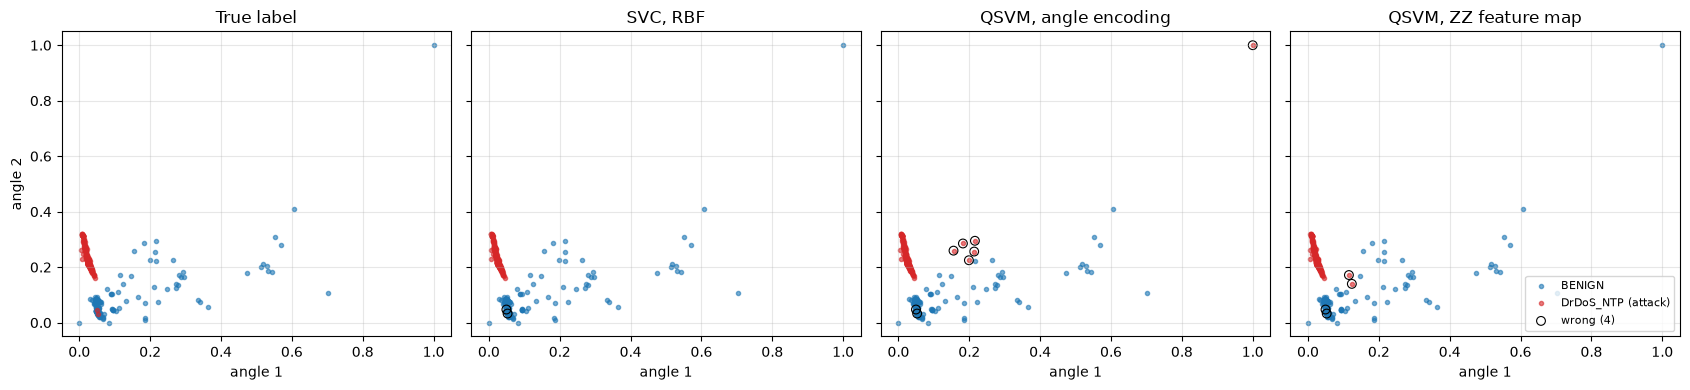

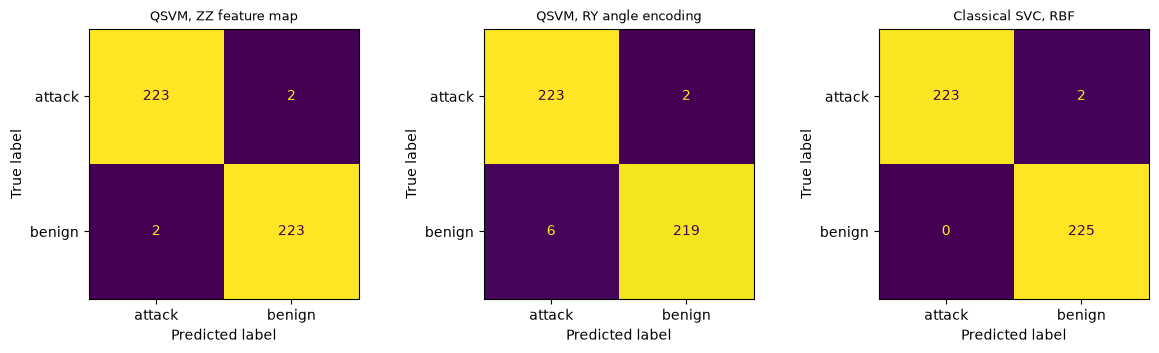

In [17]:
# Paper Fig. 5 analogue: the test flows in the 2-D PCA plane, true label and the three classifiers' predictions
panels = [("True label", yte), ("SVC, RBF", exp1_pred["Classical SVC, RBF"]),
          ("QSVM, angle encoding", exp1_pred["QSVM, RY angle encoding (2 qubits)"]),
          ("QSVM, ZZ feature map", exp1_pred["QSVM, ZZ feature map (2 qubits)"])]
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, (title, lab) in zip(axes, panels):
    for k in (0, 1):
        m = lab == k
        ax.scatter(A_te[m, 0], A_te[m, 1], s=9, alpha=0.6, c=colors[k], label=CLASS_NAMES[k])
    wrong = lab != yte
    if title != "True label":
        ax.scatter(A_te[wrong, 0], A_te[wrong, 1], s=40, facecolors="none", edgecolors="k", linewidths=0.8, label=f"wrong ({wrong.sum()})")
    ax.set_title(title); ax.grid(alpha=0.3); ax.set_xlabel("angle 1")
axes[0].set_ylabel("angle 2"); axes[3].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, nm in zip(axes, ["QSVM, ZZ feature map (2 qubits)", "QSVM, RY angle encoding (2 qubits)", "Classical SVC, RBF"]):
    ConfusionMatrixDisplay(confusion_matrix(yte, exp1_pred[nm], labels=[1, 0]), display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(nm.replace(" (2 qubits)", ""), fontsize=9)
plt.tight_layout(); plt.show()

## 11. Seeing the vanishing similarity: kernel values against the number of qubits

Before the accuracy experiments, look at the phenomenon itself. We take real flows, preprocess them as above with `n` components, and compute the kernel matrix of `CONC_POINTS` different flows. For two different flows `K(x, y)` is some number between 0 and 1; "vanishing similarity" means these off-diagonal numbers all become tiny and nearly equal (they concentrate around a value near 0), so the kernel matrix tends to the identity. We measure the **mean** and the **spread** (variance) of the off-diagonal entries for `n` from 2 to 20 qubits, for the fidelity kernel and the proposed kernel, and compare the variance with the Haar-random upper bounds of the paper's Appendix A (Eqs. 10 and 11 with expressivity terms set to 0, i.e. maximally expressive maps).

Two things to keep in mind. First, the Haar bounds describe *random* circuits; the ZZ map with features in (0, 1) uses small rotation angles and is far from random, so the bound is only a guide. Second, we repeat the measurement with all features multiplied by `pi` (angles in (0, pi), the range used in the Qiskit tutorials and the other notebooks of this repository): larger angles make the circuit more random and show the concentration much more clearly. This is the same real data, only a different angle scale.

This block uses the PCA and min-max fitted on a pool of 200 flows. No labels and no classifier are involved, so there is no train/test leakage to worry about.

In [18]:
def haar_bound_fidelity(n):
    return 2.0 / (2.0 ** n * (2.0 ** n + 1))

def haar_bound_proposed(n, m=M_WINDOW):
    a = (n * (2 * m - 1) - m * (m - 1)) / n ** 2 * 2.0 / (2.0 ** m * (2.0 ** m + 1))
    b = (n - m) * (n - m + 1) / n ** 2 * (1.0 / 2.0 ** m) ** 2
    return a + b

def offdiag(K):
    return K[~np.eye(len(K), dtype=bool)]

idx_c = balanced_indices(200, SEED + 7)
Xc = X_all[idx_c]
Nmax = max(CONC_QUBITS)
sc = StandardScaler().fit(Xc); pc = PCA(n_components=Nmax, random_state=SEED).fit(sc.transform(Xc))
Zc = MinMaxScaler((0, 1)).fit_transform(pc.transform(sc.transform(Xc)))      # (200, Nmax) in (0, 1)
Zc = Zc[:CONC_POINTS]
yc = y_all[idx_c][:CONC_POINTS]

conc_rows = []
t0 = time.perf_counter()
for n in CONC_QUBITS:
    for bw, label in [(1.0, "angles in (0, 1)"), (np.pi, "angles in (0, pi)")]:
        Xn = Zc[:, :n] * bw
        Kf = zz_kernel(Xn)
        row = dict(n=n, bandwidth=label, fid_mean=offdiag(Kf).mean(), fid_var=offdiag(Kf).var(), fid_small=(offdiag(Kf) < 0.05).mean())
        if n >= M_WINDOW:
            Kn = local_kernel(Xn)
            row.update(new_mean=offdiag(Kn).mean(), new_var=offdiag(Kn).var(), new_small=(offdiag(Kn) < 0.05).mean())
        conc_rows.append(row)
conc = pd.DataFrame(conc_rows)
print(f"Concentration sweep done in {seconds_since(t0):.0f} s ({CONC_POINTS} real flows, {CONC_POINTS * (CONC_POINTS - 1)} off-diagonal pairs per point)")
conc.round(6)

Concentration sweep done in 42 s (40 real flows, 1560 off-diagonal pairs per point)


,n,bandwidth,fid_mean,fid_var,fid_small,new_mean,new_var,new_small
0,2,"angles in (0, 1)",0.524333,0.089567,0.084615,NaN,NaN,NaN
1,2,"angles in (0, pi)",0.288985,0.094342,0.317949,NaN,NaN,NaN
2,4,"angles in (0, 1)",0.300759,0.110767,0.320513,0.413236,0.100745,0.061538
3,4,"angles in (0, pi)",0.158070,0.070491,0.507692,0.230723,0.072728,0.141026
4,6,"angles in (0, 1)",0.206271,0.106643,0.591026,0.461083,0.080854,0.026923
5,6,"angles in (0, pi)",0.095092,0.056229,0.800000,0.234346,0.065150,0.079487
6,8,"angles in (0, 1)",0.166937,0.092026,0.700000,0.473942,0.070137,0.007692
7,8,"angles in (0, pi)",0.069038,0.041173,0.874359,0.236649,0.059005,0.030769
8,10,"angles in (0, 1)",0.147806,0.086790,0.738462,0.505148,0.063261,0.000000
9,10,"angles in (0, pi)",0.062239,0.041063,0.885897,0.259014,0.057451,0.012821


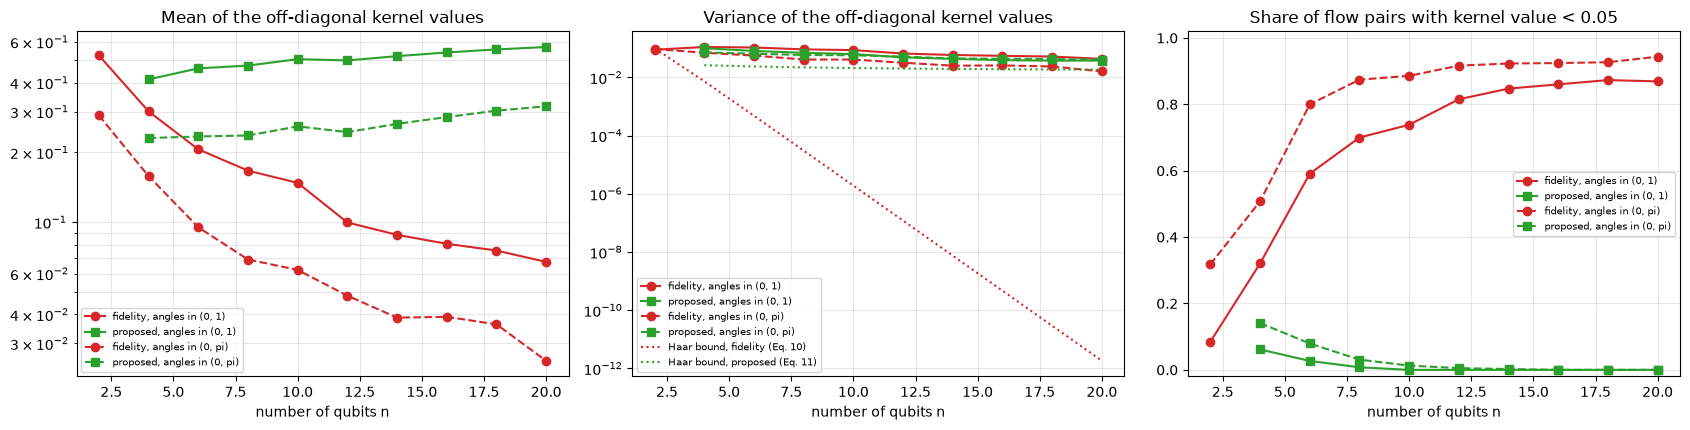

angles in (0, 1), n = 20: mean off-diagonal fidelity 6.74e-02 vs proposed 5.70e-01; variance 4.33e-02 vs 3.79e-02
angles in (0, pi), n = 20: mean off-diagonal fidelity 2.52e-02 vs proposed 3.16e-01; variance 1.61e-02 vs 4.09e-02


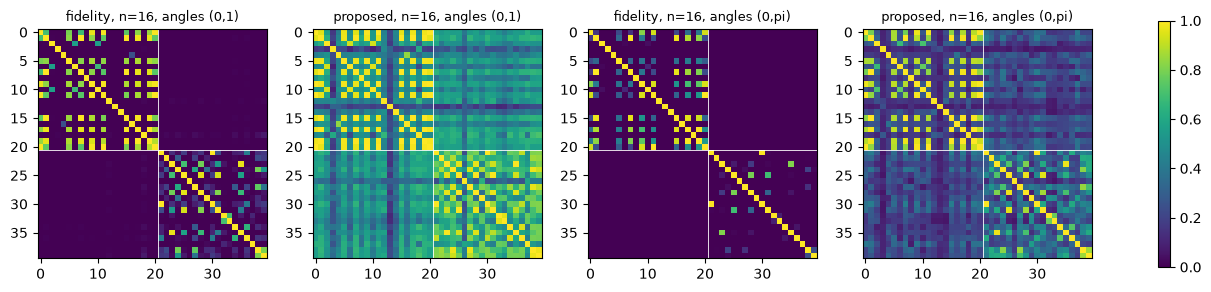

fidelity (mean off-diagonal)       p = 2.52e-02: relative standard error with 4096 shots = 0.10
proposed (mean off-diagonal)       p = 3.16e-01: relative standard error with 4096 shots = 0.02


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for bw, ls in [("angles in (0, 1)", "-"), ("angles in (0, pi)", "--")]:
    d = conc[conc.bandwidth == bw]
    axes[0].semilogy(d.n, d.fid_mean, "o" + ls, c="tab:red", label=f"fidelity, {bw}")
    axes[0].semilogy(d.n, d.new_mean, "s" + ls, c="tab:green", label=f"proposed, {bw}")
    axes[1].semilogy(d.n, d.fid_var, "o" + ls, c="tab:red", label=f"fidelity, {bw}")
    axes[1].semilogy(d.n, d.new_var, "s" + ls, c="tab:green", label=f"proposed, {bw}")
nn = np.array(CONC_QUBITS)
axes[1].semilogy(nn, [haar_bound_fidelity(n) for n in nn], ":", c="tab:red", label="Haar bound, fidelity (Eq. 10)")
axes[1].semilogy(nn[nn >= 3], [haar_bound_proposed(n) for n in nn[nn >= 3]], ":", c="tab:green", label="Haar bound, proposed (Eq. 11)")
axes[0].set_title("Mean of the off-diagonal kernel values"); axes[1].set_title("Variance of the off-diagonal kernel values")
for ax in axes[:2]:
    ax.set_xlabel("number of qubits n"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7)
for bw, ls in [("angles in (0, 1)", "-"), ("angles in (0, pi)", "--")]:
    d = conc[conc.bandwidth == bw]
    axes[2].plot(d.n, d.fid_small, "o" + ls, c="tab:red", label=f"fidelity, {bw}")
    axes[2].plot(d.n, d.new_small, "s" + ls, c="tab:green", label=f"proposed, {bw}")
axes[2].set_title("Share of flow pairs with kernel value < 0.05"); axes[2].set_xlabel("number of qubits n")
axes[2].set_ylim(-0.02, 1.02); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

n_last = max(CONC_QUBITS)
for bw in ["angles in (0, 1)", "angles in (0, pi)"]:
    r = conc[(conc.bandwidth == bw) & (conc.n == n_last)].iloc[0]
    print(f"{bw}, n = {n_last}: mean off-diagonal fidelity {r.fid_mean:.2e} vs proposed {r.new_mean:.2e}; variance {r.fid_var:.2e} vs {r.new_var:.2e}")

# Visual of the paper's idea: kernel matrices of the same flows, sorted by true class, at n = 16 (or the largest n)
n_show = 16 if 16 in CONC_QUBITS else n_last
order = np.argsort(yc, kind="stable")
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (K, ttl) in zip(axes, [(zz_kernel(Zc[:, :n_show])[np.ix_(order, order)], f"fidelity, n={n_show}, angles (0,1)"),
                               (local_kernel(Zc[:, :n_show])[np.ix_(order, order)], f"proposed, n={n_show}, angles (0,1)"),
                               (zz_kernel(Zc[:, :n_show] * np.pi)[np.ix_(order, order)], f"fidelity, n={n_show}, angles (0,pi)"),
                               (local_kernel(Zc[:, :n_show] * np.pi)[np.ix_(order, order)], f"proposed, n={n_show}, angles (0,pi)")]):
    im = ax.imshow(K, vmin=0, vmax=1, cmap="viridis"); ax.set_title(ttl, fontsize=9)
    ax.axhline((yc == 0).sum() - 0.5, c="w", lw=0.6); ax.axvline((yc == 0).sum() - 0.5, c="w", lw=0.6)
plt.colorbar(im, ax=axes, shrink=0.8); plt.show()

# Why concentration matters on hardware: finite-shot error of a kernel entry p
r = conc[(conc.bandwidth == "angles in (0, pi)") & (conc.n == n_last)].iloc[0]
for p, nm in [(max(r.fid_mean, 1e-12), "fidelity (mean off-diagonal)"), (r.new_mean, "proposed (mean off-diagonal)")]:
    print(f"{nm:34s} p = {p:.2e}: relative standard error with {SHOTS} shots = {np.sqrt((1 - p) / (p * SHOTS)):.2f}")

## 12. Experiment 2: 25 flows, 4 to 16 features (paper Table 2 and Figs. 6 and 7)

Now the number of features (and qubits) grows: 4, 6, 8, 10 and 16. The paper uses a "mini data set" of only 25 flows, split 17 for training and 8 for testing, so each test flow is worth 12.5 accuracy points. Its Table 2 shows the fidelity kernel falling to 0.375 at 16 features while the proposed kernel stays at 0.875.

With so few test flows, one random draw says little. We therefore do exactly what the paper does for **draw 0** and then repeat with `EXP2_DRAWS` different random draws of 25 flows, reporting the mean and the standard deviation. Every draw fits the preprocessing on its 17 training flows only. A classical RBF SVC on the same features is added for reference.

In [20]:
exp2_rows, exp2_K = [], {}
t0 = time.perf_counter()
for d in range(EXP2_DRAWS):
    seed_d = SEED + d
    for n in EXP2_FEATURES:
        s = make_split(EXP2_N, n, seed_d)
        A = np.vstack([s["A_tr"], s["A_te"]]); ntr = len(s["ytr"])
        Kf, Kn = zz_kernel(A), local_kernel(A)
        pf = fit_predict(Kf[:ntr, :ntr], Kf[ntr:, :ntr], s["ytr"])
        pn = fit_predict(Kn[:ntr, :ntr], Kn[ntr:, :ntr], s["ytr"])
        pr = SVC(kernel="rbf").fit(s["A_tr"], s["ytr"]).predict(s["A_te"])
        exp2_rows.append(dict(draw=d, n=n, test_size=len(s["yte"]), fidelity=accuracy_score(s["yte"], pf),
                              proposed=accuracy_score(s["yte"], pn), rbf=accuracy_score(s["yte"], pr),
                              fid_offdiag=offdiag(Kf).mean(), new_offdiag=offdiag(Kn).mean()))
        if d == 0:
            exp2_K[n] = (Kf, Kn, np.concatenate([s["ytr"], s["yte"]]))
exp2 = pd.DataFrame(exp2_rows)
print(f"Experiment 2: {EXP2_DRAWS} draws x {len(EXP2_FEATURES)} feature counts in {seconds_since(t0):.0f} s; train/test sizes {17}/{exp2.test_size.iloc[0]}")

print("\nDraw 0 only (the paper reports a single draw), accuracy:")
print(exp2[exp2.draw == 0].set_index("n")[["fidelity", "proposed", "rbf"]].round(3).T.to_string())
tab2 = exp2.groupby("n")[["fidelity", "proposed", "rbf"]].agg(["mean", "std"]).round(3)
print(f"\nMean and standard deviation over {EXP2_DRAWS} random draws:")
tab2

Experiment 2: 30 draws x 5 feature counts in 21 s; train/test sizes 17/8

Draw 0 only (the paper reports a single draw), accuracy:
n          4    6    8      10   16
fidelity  1.0  1.0  1.0  0.625  0.5
proposed  1.0  1.0  1.0  1.000  1.0
rbf       1.0  1.0  1.0  1.000  1.0

Mean and standard deviation over 30 random draws:


fidelity        proposed           rbf       
       mean    std     mean    std   mean    std
n                                               
4     0.925  0.102    0.946  0.085  0.958  0.076
6     0.888  0.120    0.938  0.079  0.950  0.078
8     0.825  0.134    0.929  0.085  0.946  0.078
10    0.733  0.149    0.933  0.091  0.954  0.077
16    0.521  0.058    0.896  0.099  0.946  0.091

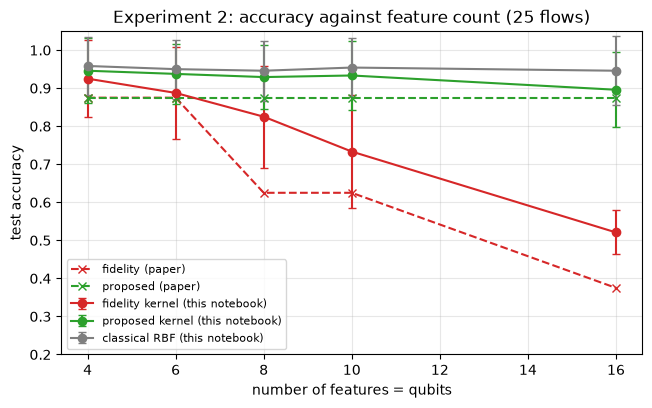

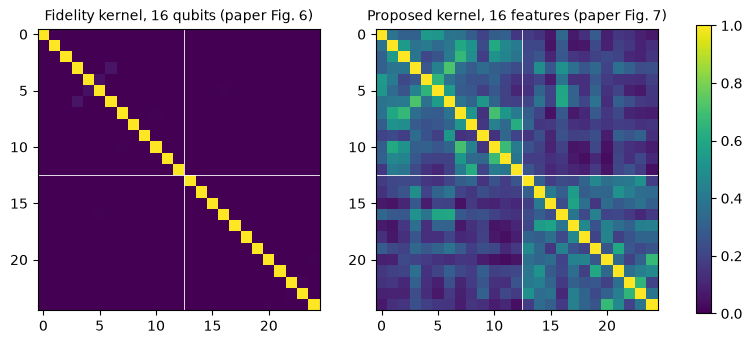

Mean off-diagonal kernel value at 16 qubits, draw 0:  fidelity 0.0005 | proposed 0.2672


In [21]:
# accuracy against the number of features, mean +- std over the draws (paper Table 2 as dashed lines)
paper_t2 = {4: (0.875, 0.875), 6: (0.875, 0.875), 8: (0.625, 0.875), 10: (0.625, 0.875), 16: (0.375, 0.875)}
g = exp2.groupby("n")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for col, c, lab in [("fidelity", "tab:red", "fidelity kernel"), ("proposed", "tab:green", "proposed kernel"), ("rbf", "tab:gray", "classical RBF")]:
    ax.errorbar(g[col].mean().index, g[col].mean(), yerr=g[col].std(), fmt="o-", c=c, capsize=3, label=f"{lab} (this notebook)")
ax.plot(list(paper_t2), [v[0] for v in paper_t2.values()], "x--", c="tab:red", label="fidelity (paper)")
ax.plot(list(paper_t2), [v[1] for v in paper_t2.values()], "x--", c="tab:green", label="proposed (paper)")
ax.set_xlabel("number of features = qubits"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.2, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Experiment 2: accuracy against feature count (25 flows)"); plt.show()

# paper Figs. 6 and 7: kernel matrices of draw 0 for 16 features (train rows first, then test rows; sorted by class)
Kf, Kn, yall2 = exp2_K[16]
order = np.argsort(yall2, kind="stable")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, K, ttl in [(axes[0], Kf, "Fidelity kernel, 16 qubits (paper Fig. 6)"), (axes[1], Kn, "Proposed kernel, 16 features (paper Fig. 7)")]:
    im = ax.imshow(K[np.ix_(order, order)], vmin=0, vmax=1, cmap="viridis"); ax.set_title(ttl, fontsize=10)
    ax.axhline((yall2 == 0).sum() - 0.5, c="w", lw=0.6); ax.axvline((yall2 == 0).sum() - 0.5, c="w", lw=0.6)
plt.colorbar(im, ax=axes, shrink=0.85); plt.show()
print("Mean off-diagonal kernel value at 16 qubits, draw 0:  fidelity %.4f | proposed %.4f" %
      (offdiag(Kf).mean(), offdiag(Kn).mean()))

## 13. Experiment 3: 100 flows, 20 features (paper Table 3 and Fig. 8)

The last experiment has 100 flows (70 for training, 30 for testing) and 20 features, so the fidelity kernel runs on **20 qubits** (1 048 576 amplitudes per state). Four classifiers are compared: the fidelity QSVM, the proposed QSVM, a classical RBF SVC, and the paper's control, a classical "multiple RBF" kernel that averages RBF kernels over the same windows of three features. If the control matched the proposed kernel, the window decomposition alone would explain the gain; the paper reports that the control equals the plain RBF, so the quantum feature map must matter.

As before, draw 0 imitates the paper's single run and further draws measure the spread. Draw 0 also gets confusion matrices, timings and the four kernel matrices of Fig. 8.

In [22]:
exp3_rows, exp3_store = [], {}
t0 = time.perf_counter()
for d in range(EXP3_DRAWS):
    seed_d = SEED + d
    s = make_split(EXP3_N, EXP3_FEATURES, seed_d)
    A = np.vstack([s["A_tr"], s["A_te"]]); ntr = len(s["ytr"]); ytr_, yte_ = s["ytr"], s["yte"]
    res, tim, kernels = {}, {}, {}
    t1 = time.perf_counter(); kernels["Fidelity-based"] = zz_kernel(A); tim["Fidelity-based"] = seconds_since(t1)
    t1 = time.perf_counter(); kernels["Proposed"] = local_kernel(A); tim["Proposed"] = seconds_since(t1)
    kernels["Classic RBF"] = rbf_kernel(A, A, gamma=1.0 / (A.shape[1] * s["A_tr"].var()))
    kernels["Classic multiple RBF"] = multi_rbf_kernel(A, A, s["A_tr"])
    preds = {}
    for name, K in kernels.items():
        preds[name] = fit_predict(K[:ntr, :ntr], K[ntr:, :ntr], ytr_)
        sc_ = scores(yte_, preds[name])
        exp3_rows.append(dict(draw=d, method=name, **sc_))
    if d == 0:
        exp3_store = dict(kernels=kernels, preds=preds, yall=np.concatenate([ytr_, yte_]), yte=yte_, ntr=ntr, times=tim, split=s)
    print(f"draw {d}: " + " | ".join(f"{r['method'][:12]} {r['accuracy']:.3f}" for r in exp3_rows[-4:]) + f"   ({seconds_since(t0):.0f} s elapsed)")
exp3 = pd.DataFrame(exp3_rows)
print("\nDraw 0 (paper-style single run), test size", len(exp3_store["yte"]), ":")
print(exp3[exp3.draw == 0].set_index("method")[["accuracy", "precision", "recall", "f1"]].round(3).to_string())
print(f"\nKernel build time, draw 0: fidelity (20 qubits) {exp3_store['times']['Fidelity-based']:.1f} s, proposed (20 windows of 3 qubits) {exp3_store['times']['Proposed']:.2f} s")
exp3.groupby("method")[["accuracy", "f1"]].agg(["mean", "std"]).round(3)

draw 0: Fidelity-bas 1.000 | Proposed 1.000 | Classic RBF 1.000 | Classic mult 1.000   (40 s elapsed)


draw 1: Fidelity-bas 0.967 | Proposed 1.000 | Classic RBF 0.967 | Classic mult 1.000   (72 s elapsed)


draw 2: Fidelity-bas 0.833 | Proposed 0.967 | Classic RBF 0.967 | Classic mult 0.967   (132 s elapsed)


draw 3: Fidelity-bas 0.767 | Proposed 0.933 | Classic RBF 0.900 | Classic mult 0.933   (185 s elapsed)


draw 4: Fidelity-bas 1.000 | Proposed 1.000 | Classic RBF 1.000 | Classic mult 1.000   (225 s elapsed)


...

draw 6: Fidelity-bas 0.900 | Proposed 0.933 | Classic RBF 0.933 | Classic mult 0.933   (326 s elapsed)


draw 7: Fidelity-bas 0.967 | Proposed 0.967 | Classic RBF 0.967 | Classic mult 0.967   (371 s elapsed)


draw 8: Fidelity-bas 1.000 | Proposed 1.000 | Classic RBF 1.000 | Classic mult 1.000   (412 s elapsed)


draw 9: Fidelity-bas 0.933 | Proposed 1.000 | Classic RBF 1.000 | Classic mult 1.000   (447 s elapsed)

Draw 0 (paper-style single run), test size 30 :
                      accuracy  precision  recall   f1
method                                                
Fidelity-based             1.0        1.0     1.0  1.0
Proposed                   1.0        1.0     1.0  1.0
Classic RBF                1.0        1.0     1.0  1.0
Classic multiple RBF       1.0        1.0     1.0  1.0

Kernel build time, draw 0: fidelity (20 qubits) 40.3 s, proposed (20 windows of 3 qubits) 0.02 s


accuracy            f1       
                         mean    std   mean    std
method                                            
Classic RBF             0.973  0.034  0.971  0.038
Classic multiple RBF    0.980  0.028  0.979  0.030
Fidelity-based          0.937  0.081  0.924  0.103
Proposed                0.980  0.028  0.979  0.030

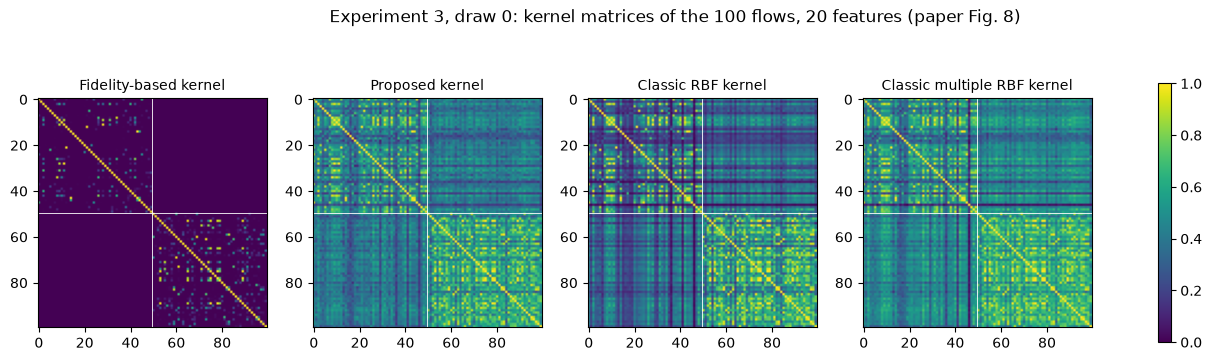

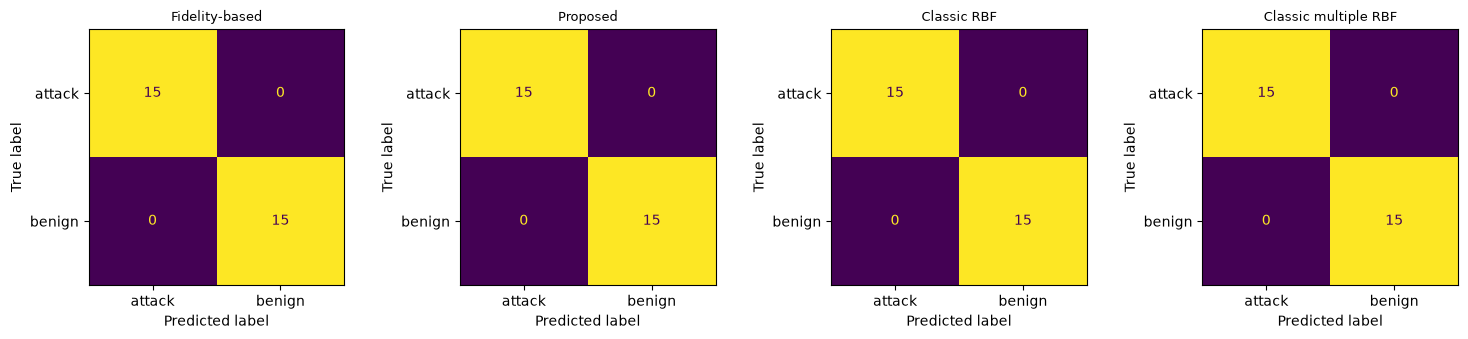

Fidelity-based         mean off-diagonal 0.0162   spread (std) 0.0922
Proposed               mean off-diagonal 0.4556   spread (std) 0.1658
Classic RBF            mean off-diagonal 0.3899   spread (std) 0.2150
Classic multiple RBF   mean off-diagonal 0.5004   spread (std) 0.1746
Max |K_RBF - K_multiRBF| = 0.4488 | mean |K_RBF - K_multiRBF| = 0.1129


In [23]:
st = exp3_store
order = np.argsort(st["yall"], kind="stable")
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, nm in zip(axes, ["Fidelity-based", "Proposed", "Classic RBF", "Classic multiple RBF"]):
    im = ax.imshow(st["kernels"][nm][np.ix_(order, order)], vmin=0, vmax=1, cmap="viridis"); ax.set_title(nm + " kernel", fontsize=10)
    ax.axhline((st["yall"] == 0).sum() - 0.5, c="w", lw=0.6); ax.axvline((st["yall"] == 0).sum() - 0.5, c="w", lw=0.6)
plt.colorbar(im, ax=axes, shrink=0.8); plt.suptitle("Experiment 3, draw 0: kernel matrices of the 100 flows, 20 features (paper Fig. 8)"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, nm in zip(axes, ["Fidelity-based", "Proposed", "Classic RBF", "Classic multiple RBF"]):
    ConfusionMatrixDisplay(confusion_matrix(st["yte"], st["preds"][nm], labels=[1, 0]), display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(nm, fontsize=9)
plt.tight_layout(); plt.show()

K_ = st["kernels"]
for nm in ["Fidelity-based", "Proposed", "Classic RBF", "Classic multiple RBF"]:
    print(f"{nm:22s} mean off-diagonal {offdiag(K_[nm]).mean():.4f}   spread (std) {offdiag(K_[nm]).std():.4f}")
print("Max |K_RBF - K_multiRBF| =", np.abs(K_["Classic RBF"] - K_["Classic multiple RBF"]).max().round(4),
      "| mean |K_RBF - K_multiRBF| =", np.abs(K_["Classic RBF"] - K_["Classic multiple RBF"]).mean().round(4))

## 14. Extension: what if the bandwidth is tuned?

The paper feeds the features to the circuit as they come out of the min-max scaler (angles between 0 and 1 radian) and never changes that scale. In the quantum kernel literature the standard remedy against concentration is exactly that: multiply the data by a **bandwidth** `b` so that the angles are small enough for the kernel to stay informative. If a tuned bandwidth already rescues the fidelity kernel at 20 qubits, then the improvement of the proposed kernel over a *fixed*-bandwidth fidelity kernel is not a fair measure of "mitigation".

We therefore choose `b` from `BANDWIDTH_GRID` for each kernel on a **validation split of the training data only** (70 training flows are split again into 49 for fitting and 21 for validation, stratified). Ties go to the value closest to 1. The test flows are never used for the choice. The classical RBF gets the same treatment on its `gamma` (a grid of scale factors). This is our addition, not part of the paper.

In [24]:
def pick_best(candidates, val_scores):
    """highest validation accuracy; ties -> the candidate closest to 1 on a log scale."""
    best = max(val_scores)
    ties = [c for c, v in zip(candidates, val_scores) if v >= best - 1e-12]
    return min(ties, key=lambda c: abs(np.log(c)))

tuned_rows, tuned_choice = [], []
t0 = time.perf_counter()
for d in range(TUNE_DRAWS):
    seed_d = SEED + d
    s = make_split(EXP3_N, EXP3_FEATURES, seed_d)
    A = np.vstack([s["A_tr"], s["A_te"]]); ntr = len(s["ytr"]); ytr_, yte_ = s["ytr"], s["yte"]
    fit_idx, val_idx = train_test_split(np.arange(ntr), test_size=0.3, stratify=ytr_, random_state=seed_d)
    Ks = {b: (zz_kernel(A * b), local_kernel(A * b)) for b in BANDWIDTH_GRID}          # all kernels of this draw
    gam0 = 1.0 / (A.shape[1] * s["A_tr"].var())
    out = {}
    for ki, name in [(0, "Fidelity-based, tuned"), (1, "Proposed, tuned")]:
        val = [accuracy_score(ytr_[val_idx], fit_predict(Ks[b][ki][np.ix_(fit_idx, fit_idx)], Ks[b][ki][np.ix_(val_idx, fit_idx)], ytr_[fit_idx]))
               for b in BANDWIDTH_GRID]
        b_best = pick_best(BANDWIDTH_GRID, val)
        K = Ks[b_best][ki]
        out[name] = (fit_predict(K[:ntr, :ntr], K[ntr:, :ntr], ytr_), b_best)
        tuned_choice.append(dict(draw=d, method=name, chosen=b_best, **{f"val b={b}": v for b, v in zip(BANDWIDTH_GRID, val)}))
    gfac = [0.1, 0.3, 1.0, 3.0, 10.0]
    val = [accuracy_score(ytr_[val_idx], SVC(kernel="rbf", gamma=gam0 * g_).fit(s["A_tr"][fit_idx], ytr_[fit_idx]).predict(s["A_tr"][val_idx])) for g_ in gfac]
    g_best = pick_best(gfac, val)
    out["Classic RBF, tuned"] = (SVC(kernel="rbf", gamma=gam0 * g_best).fit(s["A_tr"], ytr_).predict(s["A_te"]), g_best)
    tuned_choice.append(dict(draw=d, method="Classic RBF, tuned", chosen=g_best, **{f"val g={g_}": v for g_, v in zip(gfac, val)}))
    for name, (p, _) in out.items():
        tuned_rows.append(dict(draw=d, method=name, **scores(yte_, p)))
    print(f"draw {d}: " + " | ".join(f"{k} b/gamma-factor={v[1]}" for k, v in out.items()) + f"  ({seconds_since(t0):.0f} s)")
tuned = pd.DataFrame(tuned_rows)
print("\nChoices and validation accuracies:")
print(pd.DataFrame(tuned_choice).round(3).to_string(index=False))
print("\nTest accuracy of the tuned models:")
tuned.groupby("method")[["accuracy", "f1"]].agg(["mean", "std"]).round(3)

draw 0: Fidelity-based, tuned b/gamma-factor=1.0 | Proposed, tuned b/gamma-factor=1.0 | Classic RBF, tuned b/gamma-factor=1.0  (247 s)


draw 1: Fidelity-based, tuned b/gamma-factor=0.5 | Proposed, tuned b/gamma-factor=2.0 | Classic RBF, tuned b/gamma-factor=1.0  (469 s)


draw 2: Fidelity-based, tuned b/gamma-factor=1.0 | Proposed, tuned b/gamma-factor=1.0 | Classic RBF, tuned b/gamma-factor=1.0  (640 s)


draw 3: Fidelity-based, tuned b/gamma-factor=0.5 | Proposed, tuned b/gamma-factor=1.0 | Classic RBF, tuned b/gamma-factor=1.0  (839 s)


draw 4: Fidelity-based, tuned b/gamma-factor=0.5 | Proposed, tuned b/gamma-factor=1.0 | Classic RBF, tuned b/gamma-factor=1.0  (1038 s)

Choices and validation accuracies:
 draw                method  chosen  val b=0.1  val b=0.25  val b=0.5  val b=1.0  val b=2.0  val g=0.1  val g=0.3  val g=1.0  val g=3.0  val g=10.0
    0 Fidelity-based, tuned     1.0      0.905       1.000      1.000      1.000      0.857        NaN        NaN        NaN        NaN         NaN
    0       Proposed, tuned     1.0      0.476       0.905      1.000      1.000      0.952        NaN        NaN        NaN        NaN         NaN
    0    Classic RBF, tuned     1.0        NaN         NaN        NaN        NaN        NaN      0.952      1.000        1.0        1.0         1.0
    1 Fidelity-based, tuned     0.5      0.952       0.952      1.000      0.952      0.952        NaN        NaN        NaN        NaN         NaN
    1       Proposed, tuned     2.0      0.476       0.952      0.952      0.952      1.

accuracy            f1       
                          mean    std   mean    std
method                                             
Classic RBF, tuned       0.967  0.041  0.964  0.045
Fidelity-based, tuned    0.933  0.078  0.922  0.093
Proposed, tuned          0.973  0.028  0.972  0.030

## 15. Side by side with the paper

The rule for a verdict on a number is: *reproduced* when the notebook value is within 0.02 of the paper's (accuracy or F1), otherwise *not reached* (notebook lower) or *exceeded* (notebook higher), with the gap. For Experiments 2 and 3 the table uses the **mean over the random draws** (the paper has one draw with only 8 or 30 test flows, so a single value carries a sampling error of about 0.12 or 0.05), and also shows draw 0. Claims that are about shape rather than a number (a decline, a ranking, a matrix pattern) are judged by an explicit rule written in the table.

In [25]:
def verdict(paper, nb, tol=0.02):
    if abs(nb - paper) <= tol: return "reproduced"
    return ("exceeded by " if nb > paper else "not reached, gap ") + f"{abs(nb - paper):.3f}"

rows = []
e1 = exp1_df
for key, nm, pa, pf in [("ZZ feature map", "QSVM, ZZ feature map (2 qubits)", 0.995, 0.996),
                        ("Angle encoding", "QSVM, RY angle encoding (2 qubits)", 0.720, 0.819),
                        ("Classic SVC", "Classical SVC, RBF", 0.993, 0.995)]:
    rows.append(["Exp 1 (Table 1)", f"{key}: accuracy", pa, e1.loc[nm, "accuracy"], verdict(pa, e1.loc[nm, "accuracy"])])
    rows.append(["Exp 1 (Table 1)", f"{key}: F1", pf, e1.loc[nm, "f1"], verdict(pf, e1.loc[nm, "f1"])])

m2 = exp2.groupby("n")[["fidelity", "proposed"]].mean()
d0 = exp2[exp2.draw == 0].set_index("n")
for n, (pfid, pnew) in paper_t2.items():
    rows.append(["Exp 2 (Table 2), mean of draws", f"n={n} fidelity", pfid, m2.loc[n, "fidelity"], verdict(pfid, m2.loc[n, "fidelity"])])
    rows.append(["Exp 2 (Table 2), mean of draws", f"n={n} proposed", pnew, m2.loc[n, "proposed"], verdict(pnew, m2.loc[n, "proposed"])])
    rows.append(["Exp 2 (Table 2), draw 0", f"n={n} fidelity", pfid, d0.loc[n, "fidelity"], verdict(pfid, d0.loc[n, "fidelity"], tol=0.126)])
    rows.append(["Exp 2 (Table 2), draw 0", f"n={n} proposed", pnew, d0.loc[n, "proposed"], verdict(pnew, d0.loc[n, "proposed"], tol=0.126)])

m3 = exp3.groupby("method")[["accuracy", "f1"]].mean()
for key, pa, pf in [("Fidelity-based", 0.867, 0.875), ("Proposed", 1.000, 1.000), ("Classic RBF", 0.933, 0.941), ("Classic multiple RBF", 0.933, 0.941)]:
    rows.append(["Exp 3 (Table 3), mean of draws", f"{key}: accuracy", pa, m3.loc[key, "accuracy"], verdict(pa, m3.loc[key, "accuracy"])])
    rows.append(["Exp 3 (Table 3), mean of draws", f"{key}: F1", pf, m3.loc[key, "f1"], verdict(pf, m3.loc[key, "f1"])])
    x0 = exp3[(exp3.draw == 0) & (exp3.method == key)].iloc[0]
    rows.append(["Exp 3 (Table 3), draw 0", f"{key}: accuracy", pa, x0.accuracy, verdict(pa, x0.accuracy, tol=0.034)])
comp = pd.DataFrame(rows, columns=["Where", "Quantity", "Paper", "Notebook", "Verdict"])
comp["Paper"] = comp["Paper"].round(3); comp["Notebook"] = comp["Notebook"].round(3)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)
print(comp.to_string(index=False))

                         Where                       Quantity  Paper  Notebook                Verdict
               Exp 1 (Table 1)       ZZ feature map: accuracy  0.995     0.991             reproduced
               Exp 1 (Table 1)             ZZ feature map: F1  0.996     0.991             reproduced
               Exp 1 (Table 1)       Angle encoding: accuracy  0.720     0.982      exceeded by 0.262
               Exp 1 (Table 1)             Angle encoding: F1  0.819     0.982      exceeded by 0.163
               Exp 1 (Table 1)          Classic SVC: accuracy  0.993     0.996             reproduced
               Exp 1 (Table 1)                Classic SVC: F1  0.995     0.996             reproduced
Exp 2 (Table 2), mean of draws                   n=4 fidelity  0.875     0.925      exceeded by 0.050
Exp 2 (Table 2), mean of draws                   n=4 proposed  0.875     0.946      exceeded by 0.071
       Exp 2 (Table 2), draw 0                   n=4 fidelity  0.875     1.000    

In [26]:
# claims about shape (each with an explicit rule)
claims = []
drop_fid = m2.loc[min(EXP2_FEATURES), "fidelity"] - m2.loc[max(EXP2_FEATURES), "fidelity"]
claims.append(("Exp 2: fidelity accuracy declines clearly from 4 to 16 features (paper: 0.875 to 0.375, drop 0.50)",
               f"drop of the mean over draws = {drop_fid:.3f}", "reproduced" if drop_fid >= 0.25 else "not reached"))
spread_new = m2["proposed"].max() - m2["proposed"].min()
claims.append(("Exp 2: proposed accuracy stays flat with the feature count (paper: constant 0.875)",
               f"max - min of the mean over draws = {spread_new:.3f}", "reproduced" if spread_new <= 0.125 else "not reached"))
gap16 = m2.loc[16, "proposed"] - m2.loc[16, "fidelity"]
claims.append(("Exp 2: proposed beats fidelity at 16 features (paper: +0.50)", f"gap of the means = {gap16:+.3f}",
               "reproduced" if gap16 > 0.1 else "not reached"))
claims.append(("Exp 2 / Figs. 6-7: proposed kernel keeps larger off-diagonal entries than the fidelity kernel at 16 qubits",
               f"mean off-diagonal {exp2[exp2.n == 16].fid_offdiag.mean():.4f} (fidelity) vs {exp2[exp2.n == 16].new_offdiag.mean():.4f} (proposed)",
               "reproduced" if exp2[exp2.n == 16].new_offdiag.mean() > 2 * exp2[exp2.n == 16].fid_offdiag.mean() else "not reached"))
rank = m3["accuracy"].sort_values(ascending=False)
others = m3["accuracy"].drop("Proposed")
if m3.loc["Proposed", "accuracy"] > others.max() + 1e-9:
    rk = "reproduced"
elif m3.loc["Proposed", "accuracy"] >= others.max() - 1e-9:
    rk = "partly: tied for first with " + ", ".join(others.index[others >= others.max() - 1e-9])
else:
    rk = "not reached"
claims.append(("Exp 3: proposed kernel is the most accurate of the four (paper: 1.000 vs 0.933, 0.933, 0.867)",
               "ranking by mean accuracy: " + ", ".join(f"{k} {v:.3f}" for k, v in rank.items()), rk))
claims.append(("Exp 3: proposed kernel beats the fidelity kernel at 20 qubits (paper: +0.133)",
               f"gap of the means = {m3.loc['Proposed', 'accuracy'] - m3.loc['Fidelity-based', 'accuracy']:+.3f} over {EXP3_DRAWS} draws",
               "reproduced" if m3.loc["Proposed", "accuracy"] - m3.loc["Fidelity-based", "accuracy"] >= 0.08 else "not reached"))
dm = (m3.loc["Classic multiple RBF", "accuracy"] - m3.loc["Classic RBF", "accuracy"])
claims.append(("Exp 3: multiple-RBF control is virtually identical to plain RBF (paper: both 0.933)",
               f"mean accuracy difference = {dm:+.3f}; kernel entries differ by {np.abs(K_['Classic RBF'] - K_['Classic multiple RBF']).mean():.3f} on average",
               "reproduced" if abs(dm) <= 0.02 else "not reached"))
c20 = conc[(conc.bandwidth == "angles in (0, pi)") & (conc.n == max(CONC_QUBITS))].iloc[0]
c20b = conc[(conc.bandwidth == "angles in (0, 1)") & (conc.n == max(CONC_QUBITS))].iloc[0]
c4 = conc[(conc.bandwidth == "angles in (0, 1)") & (conc.n == 4)].iloc[0]
claims.append(("Figs. 6-8: the fidelity kernel's off-diagonal values shrink with the number of qubits while the proposed kernel's do not",
               f"angles (0,1), n=4 -> n={max(CONC_QUBITS)}: fidelity mean {c4.fid_mean:.3f} -> {c20b.fid_mean:.3f}; proposed {c4.new_mean:.3f} -> {c20b.new_mean:.3f}; angles (0,pi), n={max(CONC_QUBITS)}: {c20.fid_mean:.3f} vs {c20.new_mean:.3f}",
               "reproduced" if (c20b.fid_mean < 0.5 * c4.fid_mean and c20b.new_mean > 0.8 * c4.new_mean) else "not reached"))
vr = c20b.fid_var / c4.fid_var
claims.append(("Appendix A: the variance of the fidelity kernel falls like 1/2^(2n) (Haar bound)",
               f"measured variance ratio n={max(CONC_QUBITS)} / n=4 = {vr:.2f}; Haar bound ratio = {haar_bound_fidelity(max(CONC_QUBITS)) / haar_bound_fidelity(4):.1e}; measured variance at n={max(CONC_QUBITS)} is {c20b.fid_var / haar_bound_fidelity(max(CONC_QUBITS)):.1e} times the bound",
               "not reached: the bound is for Haar-random maps; this map and these data are far from that regime"))
if len(tuned):
    tm = tuned.groupby("method")["accuracy"].mean()
    claims.append(("Extension (not in the paper): tuning the bandwidth rescues the fidelity kernel at 20 qubits",
                   "mean test accuracy " + ", ".join(f"{k} {v:.3f}" for k, v in tm.items()),
                   "cannot be checked against the paper (our addition)"))
claims.append(("Exp 3 numbers come from one draw of 30 test flows in the paper", "one flow = 0.033 accuracy; compare the draw-to-draw std in Section 13",
               "cannot be checked beyond the draw-0 and mean comparisons above"))
print(pd.DataFrame(claims, columns=["Claim", "Notebook evidence", "Verdict"]).to_string(index=False, max_colwidth=110))

                                                                                                         Claim                                                                                              Notebook evidence                                                                                          Verdict
            Exp 2: fidelity accuracy declines clearly from 4 to 16 features (paper: 0.875 to 0.375, drop 0.50)                                                                            drop of the mean over draws = 0.404                                                                                       reproduced
                            Exp 2: proposed accuracy stays flat with the feature count (paper: constant 0.875)                                                                       max - min of the mean over draws = 0.050                                                                                       reproduced
                                           

## 16. Reading the paper critically

* **The test sets are tiny.** Experiment 2 has 8 test flows (one flow = 12.5 accuracy points) and Experiment 3 has 30 (one flow = 3.3 points). Table 2's entries 0.875, 0.625 and 0.375 are 7, 5 and 3 correct flows out of 8. Our repeated draws show how much a single draw can move; differences smaller than a few flows should not be read as an effect.
* **On this data the "vanishing" is a gentle decline, not an exponential collapse.** The mean off-diagonal value of the fidelity kernel falls steadily with the number of qubits (Section 11), and falls faster with angles in (0, pi) than in (0, 1), while the proposed kernel keeps its off-diagonal mass. But the variance of the off-diagonal entries stays around 10^-2, many orders of magnitude above the Haar bound, and the largest off-diagonal entry stays close to 1: real flows come in tight clusters (see the scatter in Section 6), and similar flows stay similar for any feature map made of small rotations. The cause is a data set of low intrinsic dimension and small angles, not a random state space. The remedy the community normally tries first, a tuned bandwidth, is not compared in the paper; Section 14 does so.
* **The Haar-random bound is not about this circuit.** Eqs. 10 and 11 assume maximally expressive (Haar-like) feature maps (`||A||_2 = 0`). A one-layer ZZ map with data in (0, 1) is nowhere near that, so the bound is a qualitative argument (a window of 3 qubits cannot concentrate below 1/2^6 while 20 qubits can go to 1/2^40), not a prediction for the measured numbers.
* **The proposed kernel is an additive kernel of small, classically simulable pieces.** Each I-kernel lives on 8 amplitudes; we evaluated all 20 of them in a few hundredths of a second on a CPU, while the 20-qubit fidelity kernel took seconds to minutes. So the proposed kernel is not a quantum advantage candidate; it is a way to make a quantum kernel trainable at larger feature counts. The paper itself calls the work a proof of concept.
* **The window structure is arbitrary for PCA features.** The windows combine neighbouring PCA components (1-2-3, 2-3-4, ...). PCA components are uncorrelated by construction, so "neighbour" has no meaning in the data; ordering them differently would change the kernel. The cyclic ZZ map has the same arbitrariness.
* **Min-max on every component amplifies noise.** Every PCA component, including the last ones that carry almost no variance, is stretched to the full (0, 1) range. With 17 training flows and 16 components that gives rotations driven by noise. This may explain part of the fidelity kernel's failure at 16 features that has nothing to do with the Hilbert-space dimension.
* **Preprocessing leakage.** The authors fit standardisation, PCA and min-max on train and test together and flag it as a limitation. We fit on training data only; Experiment 1 shows the effect on that experiment.
* **Experiment 1's angle encoding is unspecified.** The paper's 0.720 for angle encoding is not reachable with a rotation encoding of two PCA features in (0, 1): the kernel `prod cos^2((x_a - y_a)/2)` is a smooth bump kernel like the RBF. The paper's number looks like a degenerate kernel (see the diagnostic row with a phase-only encoding), so the cause may be an implementation detail not in the text.
* **Sampling.** The file holds 84 attack flows per benign flow. The paper does not state its class balance; results depend on it.
* **Cost on hardware.** On a real device each kernel entry is a probability estimated from shots. A fidelity entry of size p needs about 1/(p * relative error^2) shots. The proposed kernel needs n circuits per pair but each entry is large and cheap to estimate.

## 17. Exercises

1. Change `EXP2_FEATURES` to `[3, 12, 14]` and repeat Experiment 2. At which feature count does the fidelity kernel's mean accuracy drop below 0.7?
2. Replace the cyclic coupling by `cyclic=False` in `zz_circuit` and `zz_kernel` for the global map. Does the concentration plot change?
3. Use windows of size 2 or 5 instead of 3 in `local_kernel` (this needs a small change to `local_windows`). How does the off-diagonal mean at 20 qubits depend on `m`?
4. Weight the I-kernels by their validation accuracy instead of averaging them (the paper's suggestion for future work). Does it help on the 100-flow experiment?
5. Replace the PCA-and-min-max step by selecting the 20 features with the largest ANOVA F-score (`SelectKBest`) and scaling them to (0, 1). Is the fidelity kernel still worse than the proposed one?